# Evolución del precio del boleto y la demanda de viajes en el Subte de Buenos Aires (2014-2019)

**Trabajo Final Integrador — Tercera entrega**  
Universidad del Gran Rosario — Licenciatura en Ciencia de Datos  
Grupo 32: Katherine Contreras, Mateo Maibach, Joaquín Betes, Emilce Robles y Silvina Moyano

Este notebook reproduce el análisis descriptivo y la estimación de elasticidad-precio que se presentan en el informe final. Incluye las tablas procesadas y las figuras necesarias, por lo que se ejecuta de principio a fin sin pasos previos.

**Requisitos:** `pandas`, `numpy`, `matplotlib` y `statsmodels` (en Google Colab ya vienen preinstalados).

**Ejecución en Google Colab:** subir la carpeta `entrega_colab` a Google Drive y abrir este notebook desde allí. La primera celda localiza la carpeta del proyecto automáticamente y monta Drive si hace falta. Luego usar *Entorno de ejecución → Ejecutar todas*.

In [ ]:
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import statsmodels.formula.api as smf


def buscar_raiz():
    """Devuelve la carpeta que contiene data/processed/panel_mensual.csv."""
    marcador = Path("data") / "processed" / "panel_mensual.csv"

    # 1) Carpeta actual, sus padres y la subcarpeta entrega_colab (ejecución local).
    actual = Path.cwd().resolve()
    for carpeta in [actual, actual / "entrega_colab", *actual.parents]:
        if (carpeta / marcador).exists():
            return carpeta

    # 2) Ubicaciones habituales en Google Colab.
    content = Path("/content")
    candidatas = [
        content,
        content / "entrega_colab",
        content / "drive" / "MyDrive" / "entrega_colab",
        content / "drive" / "MyDrive" / "tp3" / "entrega_colab",
    ]
    if content.exists():
        candidatas += sorted(p for p in content.glob("*/") if p.is_dir())
    mydrive = content / "drive" / "MyDrive"
    if mydrive.exists():
        candidatas += sorted(p for p in mydrive.glob("*/") if p.is_dir())
        candidatas += sorted(p for p in mydrive.glob("*/*/") if p.is_dir())
    for carpeta in candidatas:
        if (carpeta / marcador).exists():
            return carpeta

    # 3) Búsqueda acotada dentro de /content (máximo 4 niveles).
    if content.exists():
        for carpeta, subcarpetas, _ in os.walk(content):
            ruta = Path(carpeta)
            if len(ruta.relative_to(content).parts) >= 4:
                subcarpetas[:] = []
            else:
                subcarpetas[:] = [
                    s for s in subcarpetas
                    if s not in {"drive", ".git", ".venv", "__pycache__"}
                ]
            if (ruta / marcador).exists():
                return ruta

    return None


ROOT = buscar_raiz()

# En Colab: si no se encontró, montar Drive y volver a buscar.
if ROOT is None:
    try:
        from google.colab import drive

        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
        ROOT = buscar_raiz()
    except Exception:
        pass

if ROOT is None:
    ROOT = Path.cwd()

PROC = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

assert (PROC / "panel_mensual.csv").exists(), (
    "No se encontraron las tablas procesadas. Verificar que la carpeta data/processed "
    "esté junto al notebook o dentro de entrega_colab en /content."
)
print("Raíz del proyecto:", ROOT)

## 1. Carga de datos

Se cargan las tablas livianas generadas por el ETL. La base completa de 70 millones de registros queda en `data/processed/subte.duckdb`; para el análisis se usan agregados mensuales, anuales, por línea y por estación.

In [3]:
archivos = {
    "calidad": ("calidad_datos.csv", None),
    "panel": ("panel_mensual.csv", ["fecha"]),
    "panel_linea": ("panel_linea_mes.csv", ["fecha"]),
    "tarifa": ("tarifa_mensual.csv", ["fecha"]),
    "demanda_mensual": ("demanda_mensual_total.csv", ["fecha"]),
    "demanda_anual": ("demanda_anual_total.csv", None),
    "demanda_linea": ("demanda_anual_linea.csv", None),
    "demanda_estacion": ("demanda_estacion_anual.csv", None),
    "catalogo": ("estaciones_catalogo.csv", None),
    "nuevas": ("nuevas_estaciones.csv", None),
    "comparacion": ("comparacion_viajes_anual.csv", None),
}

datos = {}
for nombre, (archivo, fechas) in archivos.items():
    datos[nombre] = pd.read_csv(
        PROC / archivo, encoding="utf-8-sig", parse_dates=fechas
    )

for nombre, df in datos.items():
    print(f"{nombre:20s} {df.shape[0]:5d} filas x {df.shape[1]:2d} columnas")

print("\nRango temporal del panel:", datos["panel"]["fecha"].min().date(), "a", datos["panel"]["fecha"].max().date())
print("Rango temporal de la tarifa:", datos["tarifa"]["fecha"].min().date(), "a", datos["tarifa"]["fecha"].max().date())

calidad                  6 filas x 18 columnas
panel                   72 filas x 11 columnas
panel_linea            432 filas x 11 columnas
tarifa                  64 filas x 12 columnas
demanda_mensual         72 filas x  5 columnas
demanda_anual            6 filas x  2 columnas
demanda_linea           36 filas x  3 columnas
demanda_estacion       517 filas x  4 columnas
catalogo                90 filas x  8 columnas
nuevas                   7 filas x  8 columnas
comparacion              6 filas x  5 columnas

Rango temporal del panel: 2014-01-01 a 2019-12-01
Rango temporal de la tarifa: 2014-01-01 a 2019-04-01


## 2. Calidad y cobertura

Se comparan las filas leídas y válidas de cada archivo, la cobertura de días y los totales de viajes. El control clave es que la suma de molinetes coincida con `viajes_anual.csv`.

In [4]:
calidad = datos["calidad"].copy()
tabla_calidad = calidad[[
    "anio", "filas_leidas", "filas_validas", "filas_descartadas",
    "fechas_distintas", "cobertura_dias_pct", "estaciones_distintas",
    "porcentaje_cero", "duplicados_clave", "suma_total",
]].copy()
tabla_calidad["suma_total"] = (tabla_calidad["suma_total"] / 1_000_000).round(1)
tabla_calidad.columns = [
    "Año", "Filas leídas", "Filas válidas", "Filas descartadas",
    "Días con registro", "Cobertura (%)", "Estaciones (nombres)",
    "Registros en cero (%)", "Duplicados", "Viajes (millones)",
]
display(tabla_calidad)

comparacion = datos["comparacion"].copy()
comparacion["viajes_molinetes"] = (comparacion["viajes_molinetes"] / 1_000_000).round(1)
comparacion["viajes_anual"] = (comparacion["viajes_anual"] / 1_000_000).round(1)
comparacion.columns = ["Año", "Molinetes (mill.)", "Viajes anual (mill.)", "Diferencia", "Diferencia (%)"]
display(comparacion)

print("Total de filas leídas en los seis archivos:", f"{calidad['filas_leidas'].sum():,.0f}")
print("Total de filas válidas:", f"{calidad['filas_validas'].sum():,.0f}")
print("Diferencia máxima contra viajes_anual.csv:", comparacion["Diferencia"].abs().max())

,Año,Filas leídas,Filas válidas,Filas descartadas,Días con registro,Cobertura (%),Estaciones (nombres),Registros en cero (%),Duplicados,Viajes (millones)
0,2014,10857244,10857244,0,364,99.730,80,4.720,0,255.200
1,2015,10958582,10958582,0,365,100.000,82,0.940,0,282.500
2,2016,11542322,11542322,0,366,100.000,83,1.100,0,314.400
3,2017,11938476,11938476,0,365,100.000,83,1.370,0,328.700
4,2018,12136454,12058191,78263,365,100.000,85,2.170,0,348.400
5,2019,12662343,12662343,0,362,99.180,86,1.490,0,341.300


,Año,Molinetes (mill.),Viajes anual (mill.),Diferencia,Diferencia (%)
0,2014,255.200,255.200,0.000,0.000
1,2015,282.500,282.500,0.000,0.000
2,2016,314.400,314.400,0.000,0.000
3,2017,328.700,328.700,0.000,0.000
4,2018,348.400,348.400,0.000,0.000
5,2019,341.300,341.300,0.000,0.000


Total de filas leídas en los seis archivos: 70,095,421
Total de filas válidas: 70,017,158
Diferencia máxima contra viajes_anual.csv: 0.0


## 3. Evolución de la tarifa

La tarifa nominal se deflacta con el IPC CABA (base diciembre 2016 = 100). La serie de tarifa termina en abril de 2019, por lo que el análisis tarifa-demanda se restringe a ese mes.

,Fecha,Tarifa anterior ($),Tarifa nueva ($),Var. nominal (%),Tarifa real anterior ($ dic-2016),Tarifa real nueva ($ dic-2016),Var. real (%)
0,2014-01,NaN,3.500,NaN,NaN,8.250,NaN
2,2014-03,3.500,4.500,28.570,7.910,9.810,24.040
34,2016-11,4.500,7.500,66.670,4.650,7.590,63.430
55,2018-08,7.500,12.500,66.670,4.980,8.000,60.790
58,2018-11,12.500,13.500,8.000,7.170,7.530,5.070
59,2018-12,13.500,14.500,7.410,7.530,7.900,4.910
60,2019-01,14.500,15.500,6.900,7.900,8.140,2.970
61,2019-02,15.500,16.500,6.450,8.140,8.380,2.980
63,2019-04,16.500,19.000,15.150,8.060,8.950,11.050


Tarifa nominal: $3.50 (ene-2014) -> $19.00 (abr-2019), 442.9%
Tarifa real:    $8.25 -> $8.95 (dic-2016), 8.4%
IPC CABA:       400.6% en el mismo período


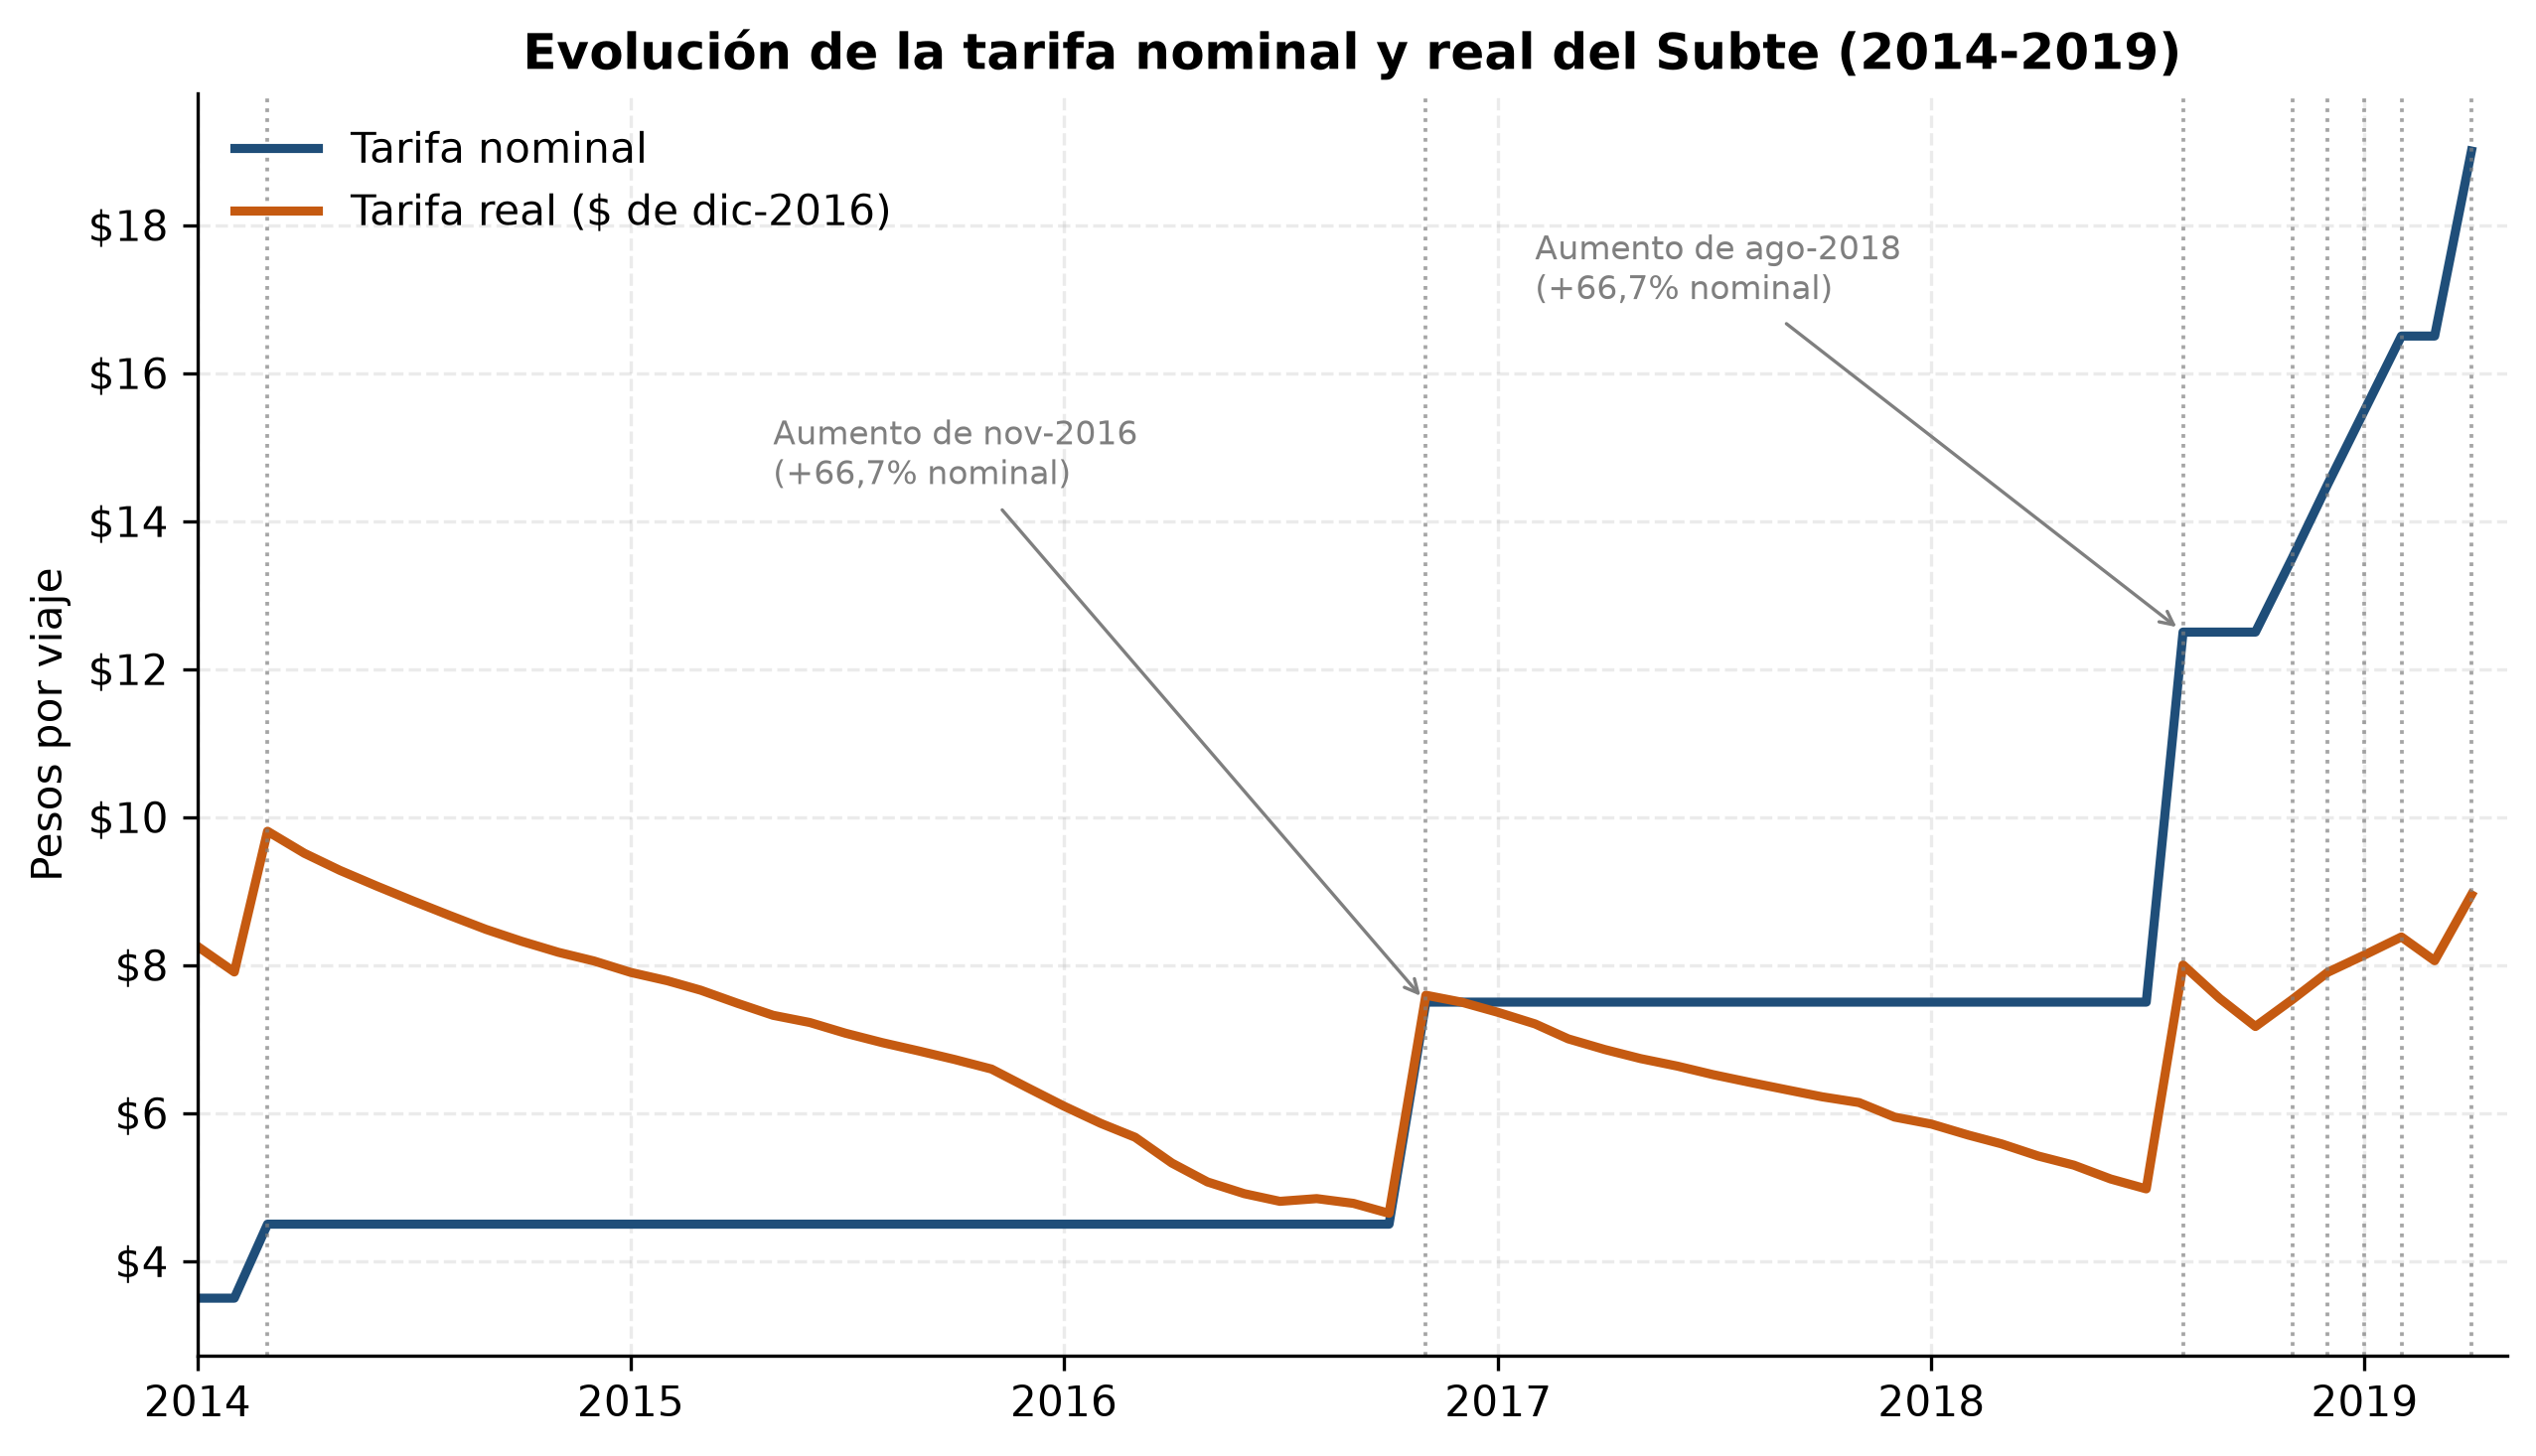

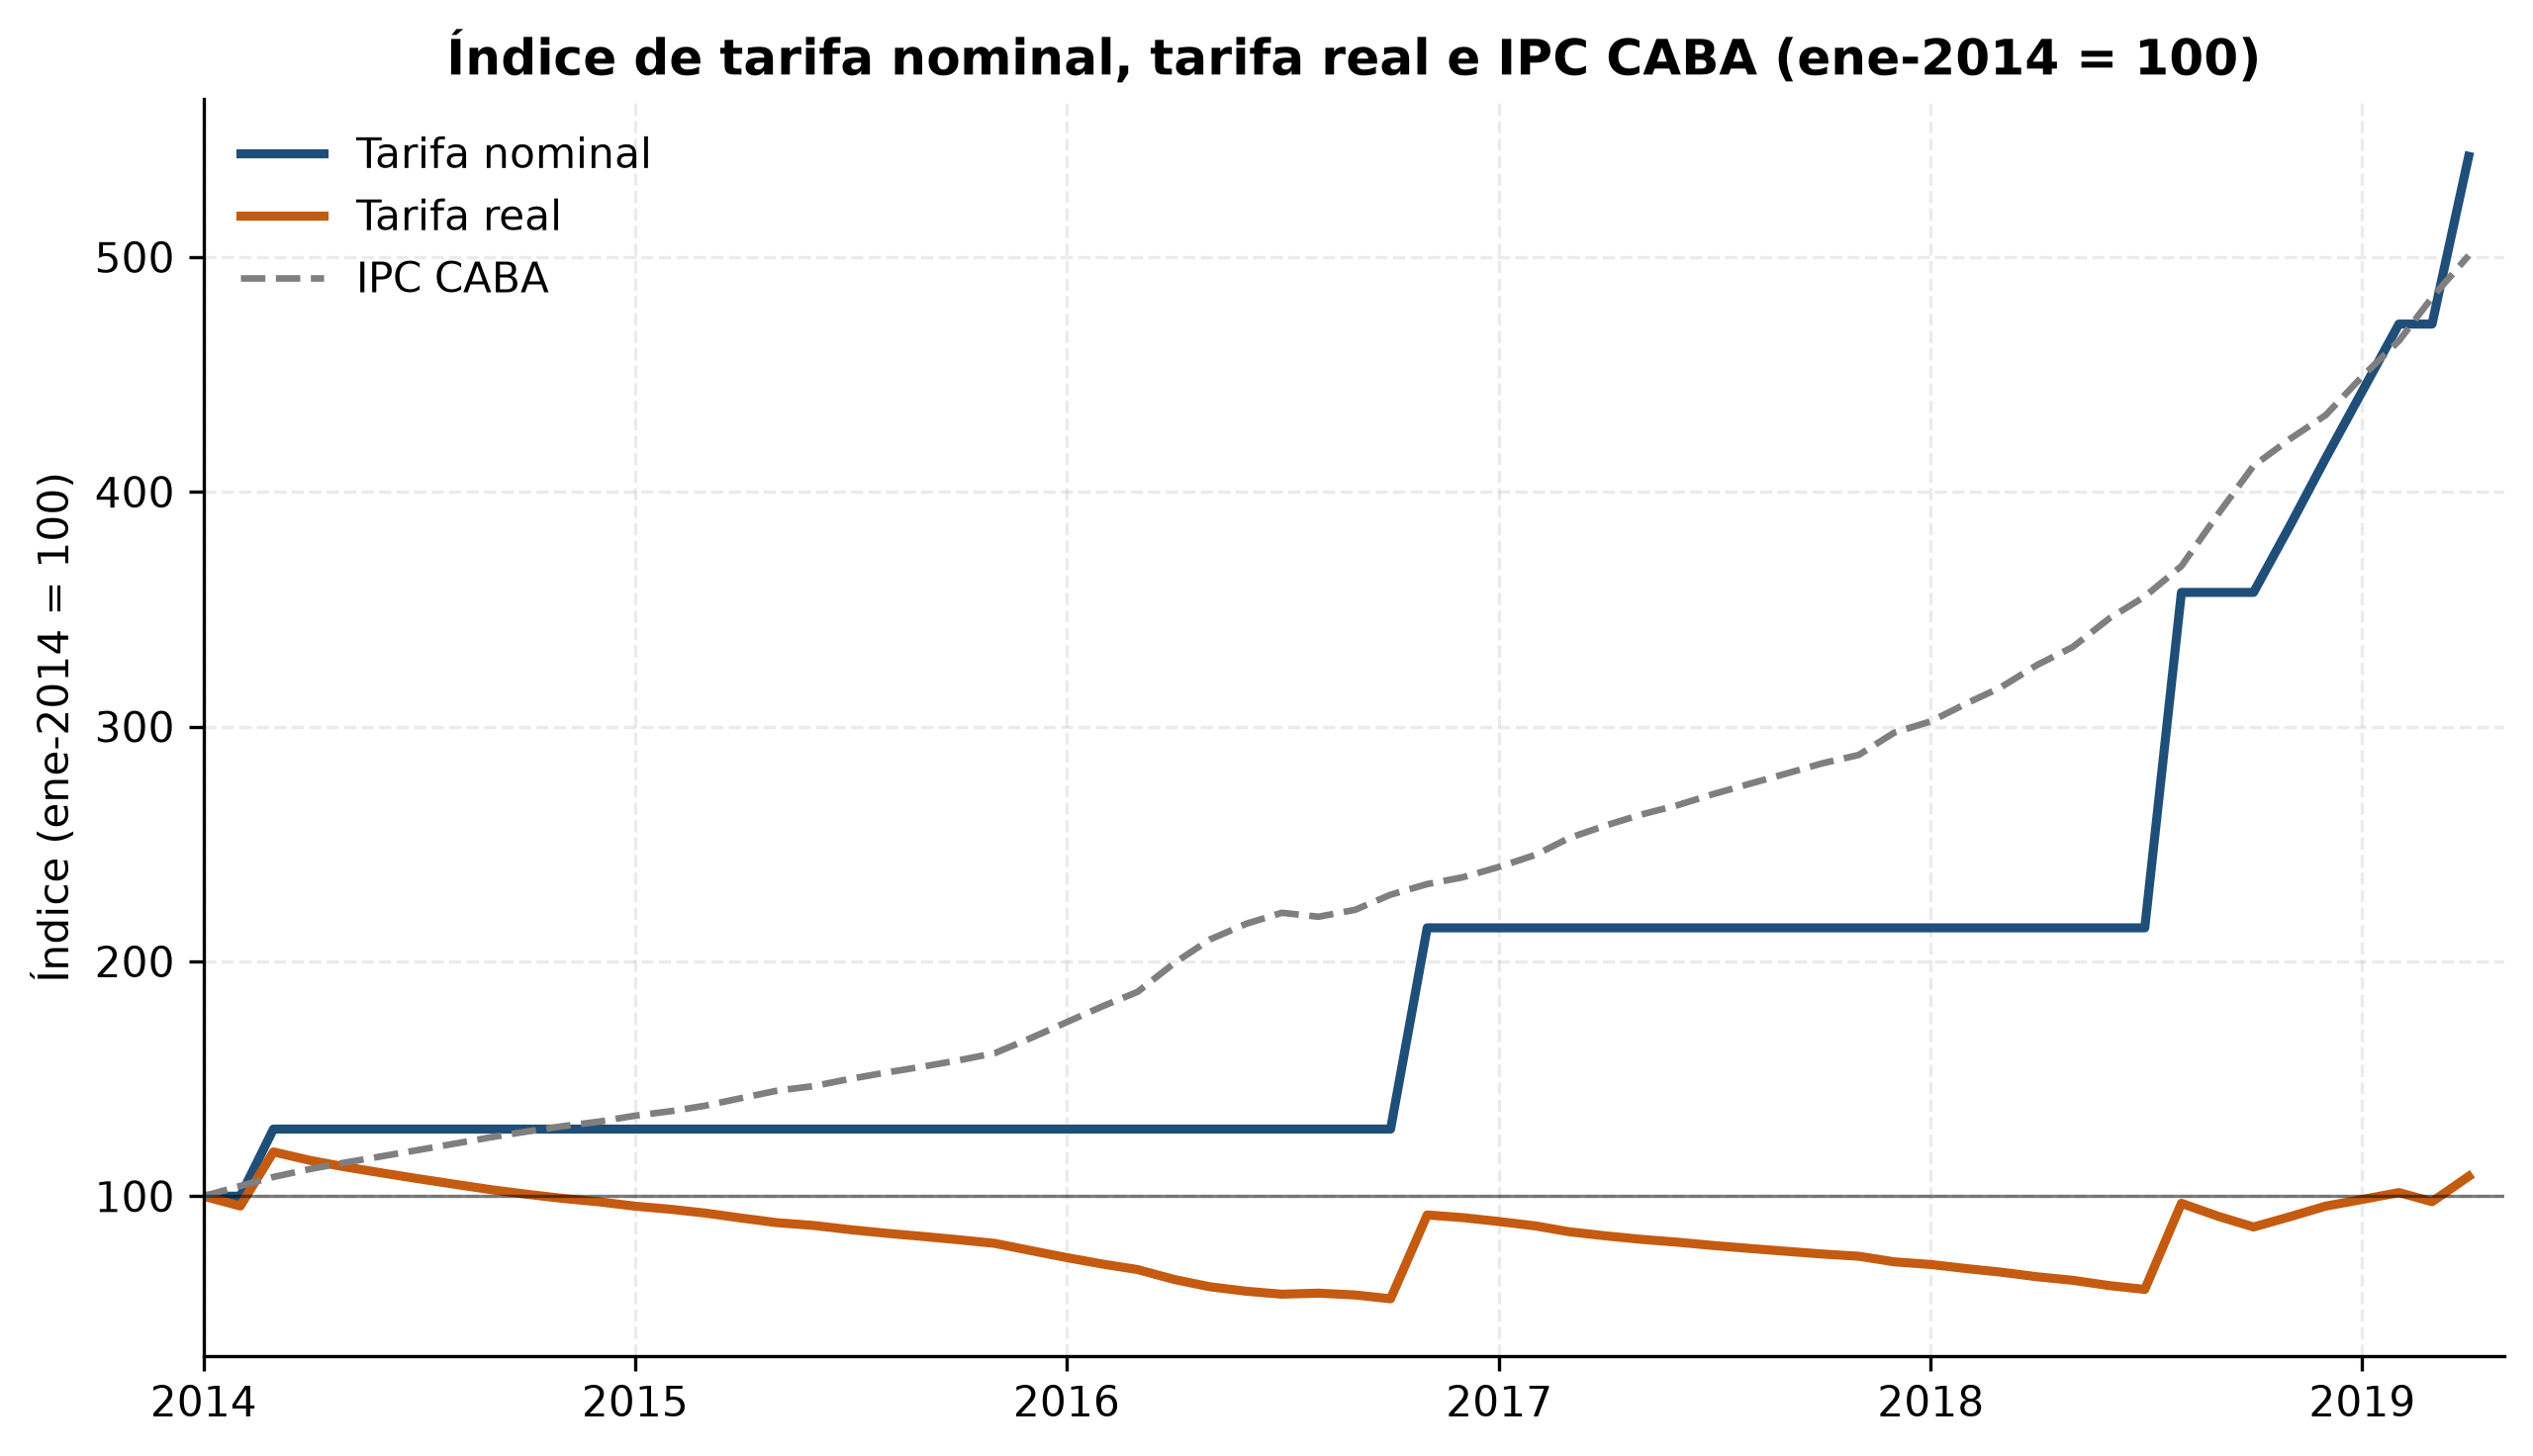

In [5]:
tarifa = datos["tarifa"].sort_values("fecha").reset_index(drop=True)

cambios = tarifa[tarifa["cambio_tarifario"]].copy()
cambios["tarifa_anterior"] = tarifa["precio_nominal"].shift(1)
cambios["real_anterior"] = tarifa["precio_real"].shift(1)
tabla_cambios = cambios[[
    "fecha", "tarifa_anterior", "precio_nominal", "var_nominal_pct",
    "real_anterior", "precio_real", "var_real_pct",
]].copy()
tabla_cambios.columns = [
    "Fecha", "Tarifa anterior ($)", "Tarifa nueva ($)", "Var. nominal (%)",
    "Tarifa real anterior ($ dic-2016)", "Tarifa real nueva ($ dic-2016)", "Var. real (%)",
]
tabla_cambios["Fecha"] = tabla_cambios["Fecha"].dt.strftime("%Y-%m")
display(tabla_cambios.round(2))

ini = tarifa.iloc[0]
fin = tarifa[tarifa["fecha"] == "2019-04-01"].iloc[0]
print(f"Tarifa nominal: ${ini['precio_nominal']:.2f} (ene-2014) -> ${fin['precio_nominal']:.2f} (abr-2019), {((fin['precio_nominal']/ini['precio_nominal']-1)*100):.1f}%")
print(f"Tarifa real:    ${ini['precio_real']:.2f} -> ${fin['precio_real']:.2f} (dic-2016), {((fin['precio_real']/ini['precio_real']-1)*100):.1f}%")
print(f"IPC CABA:       {((fin['ipc_caba']/ini['ipc_caba']-1)*100):.1f}% en el mismo período")

display(Image(filename=str(FIG / "fig01_tarifa_nominal_real.png")))
display(Image(filename=str(FIG / "fig02_indice_tarifa_ipc.png")))

## 4. Evolución de la demanda total

La demanda se mide con los viajes registrados en molinetes. Se presentan los totales anuales, la variación interanual y la serie mensual con media móvil de 12 meses.

,Año,Viajes (millones),Variación interanual (%)
0,2014,255.200,NaN
1,2015,282.500,10.709
2,2016,314.400,11.291
3,2017,328.700,4.543
4,2018,348.400,5.993
5,2019,341.300,-2.026


Promedio diario de viajes (millones):
anio
2014   0.701
2015   0.774
2016   0.859
2017   0.901
2018   0.955
2019   0.943
Variación del promedio diario 2018-2019: -1.2%


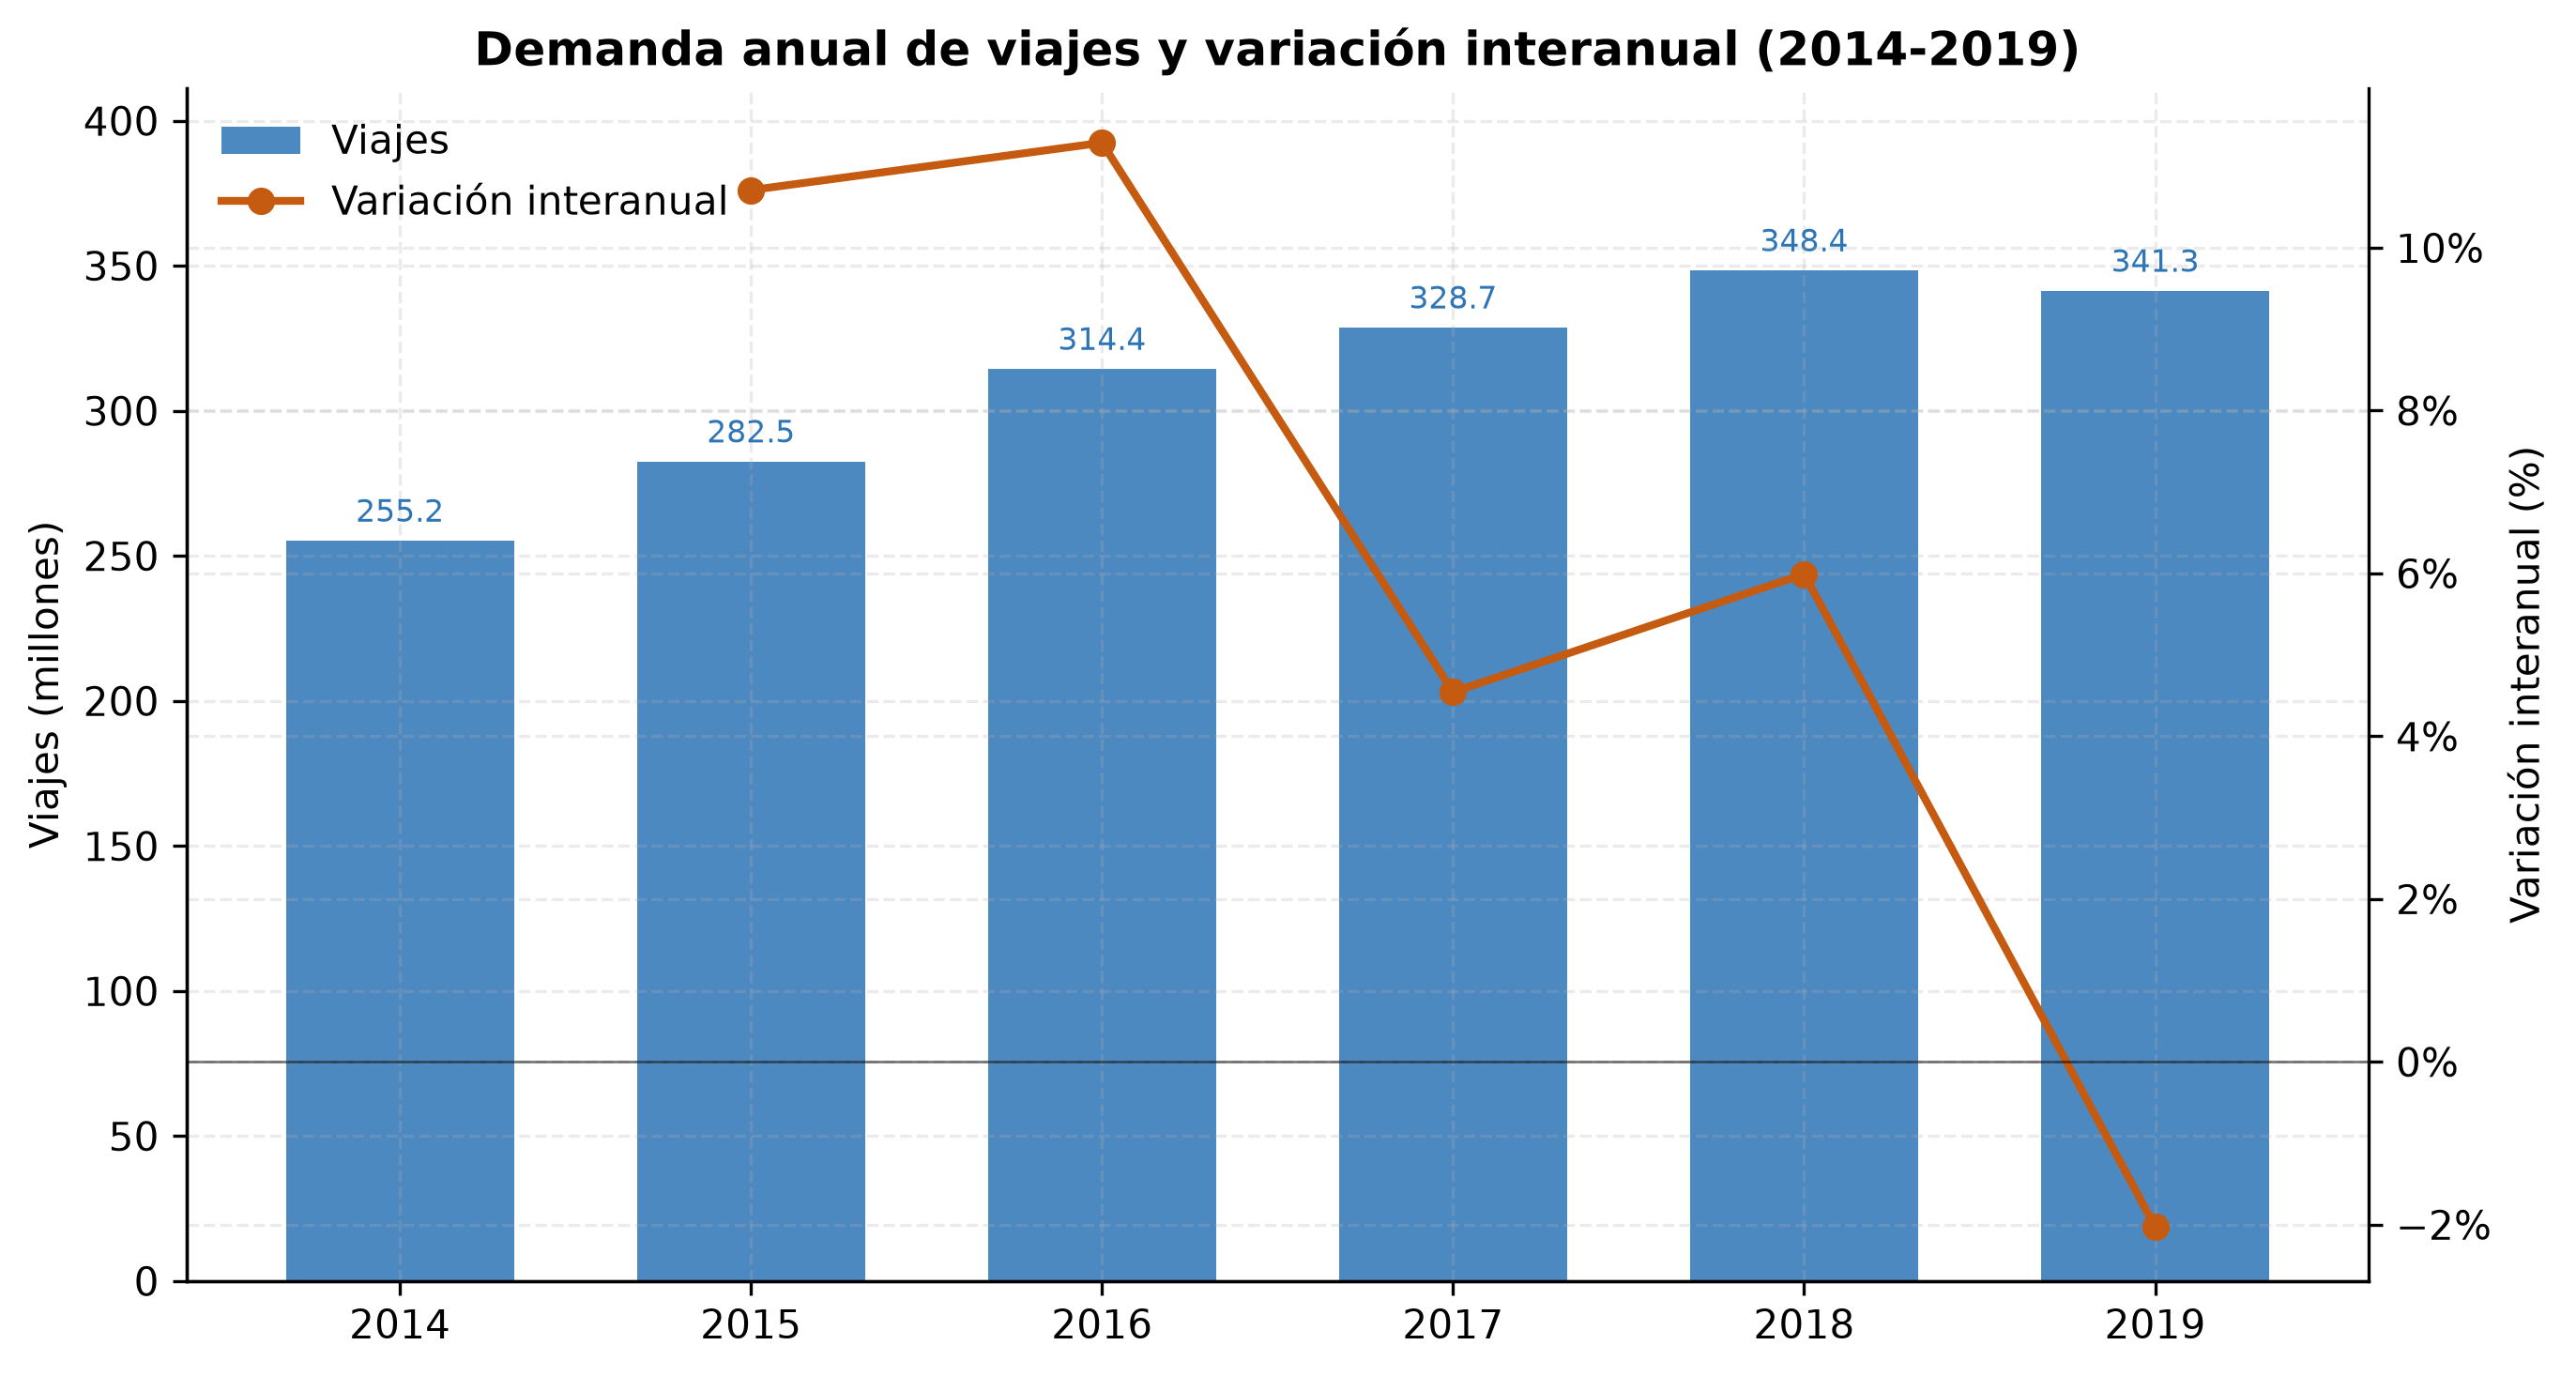

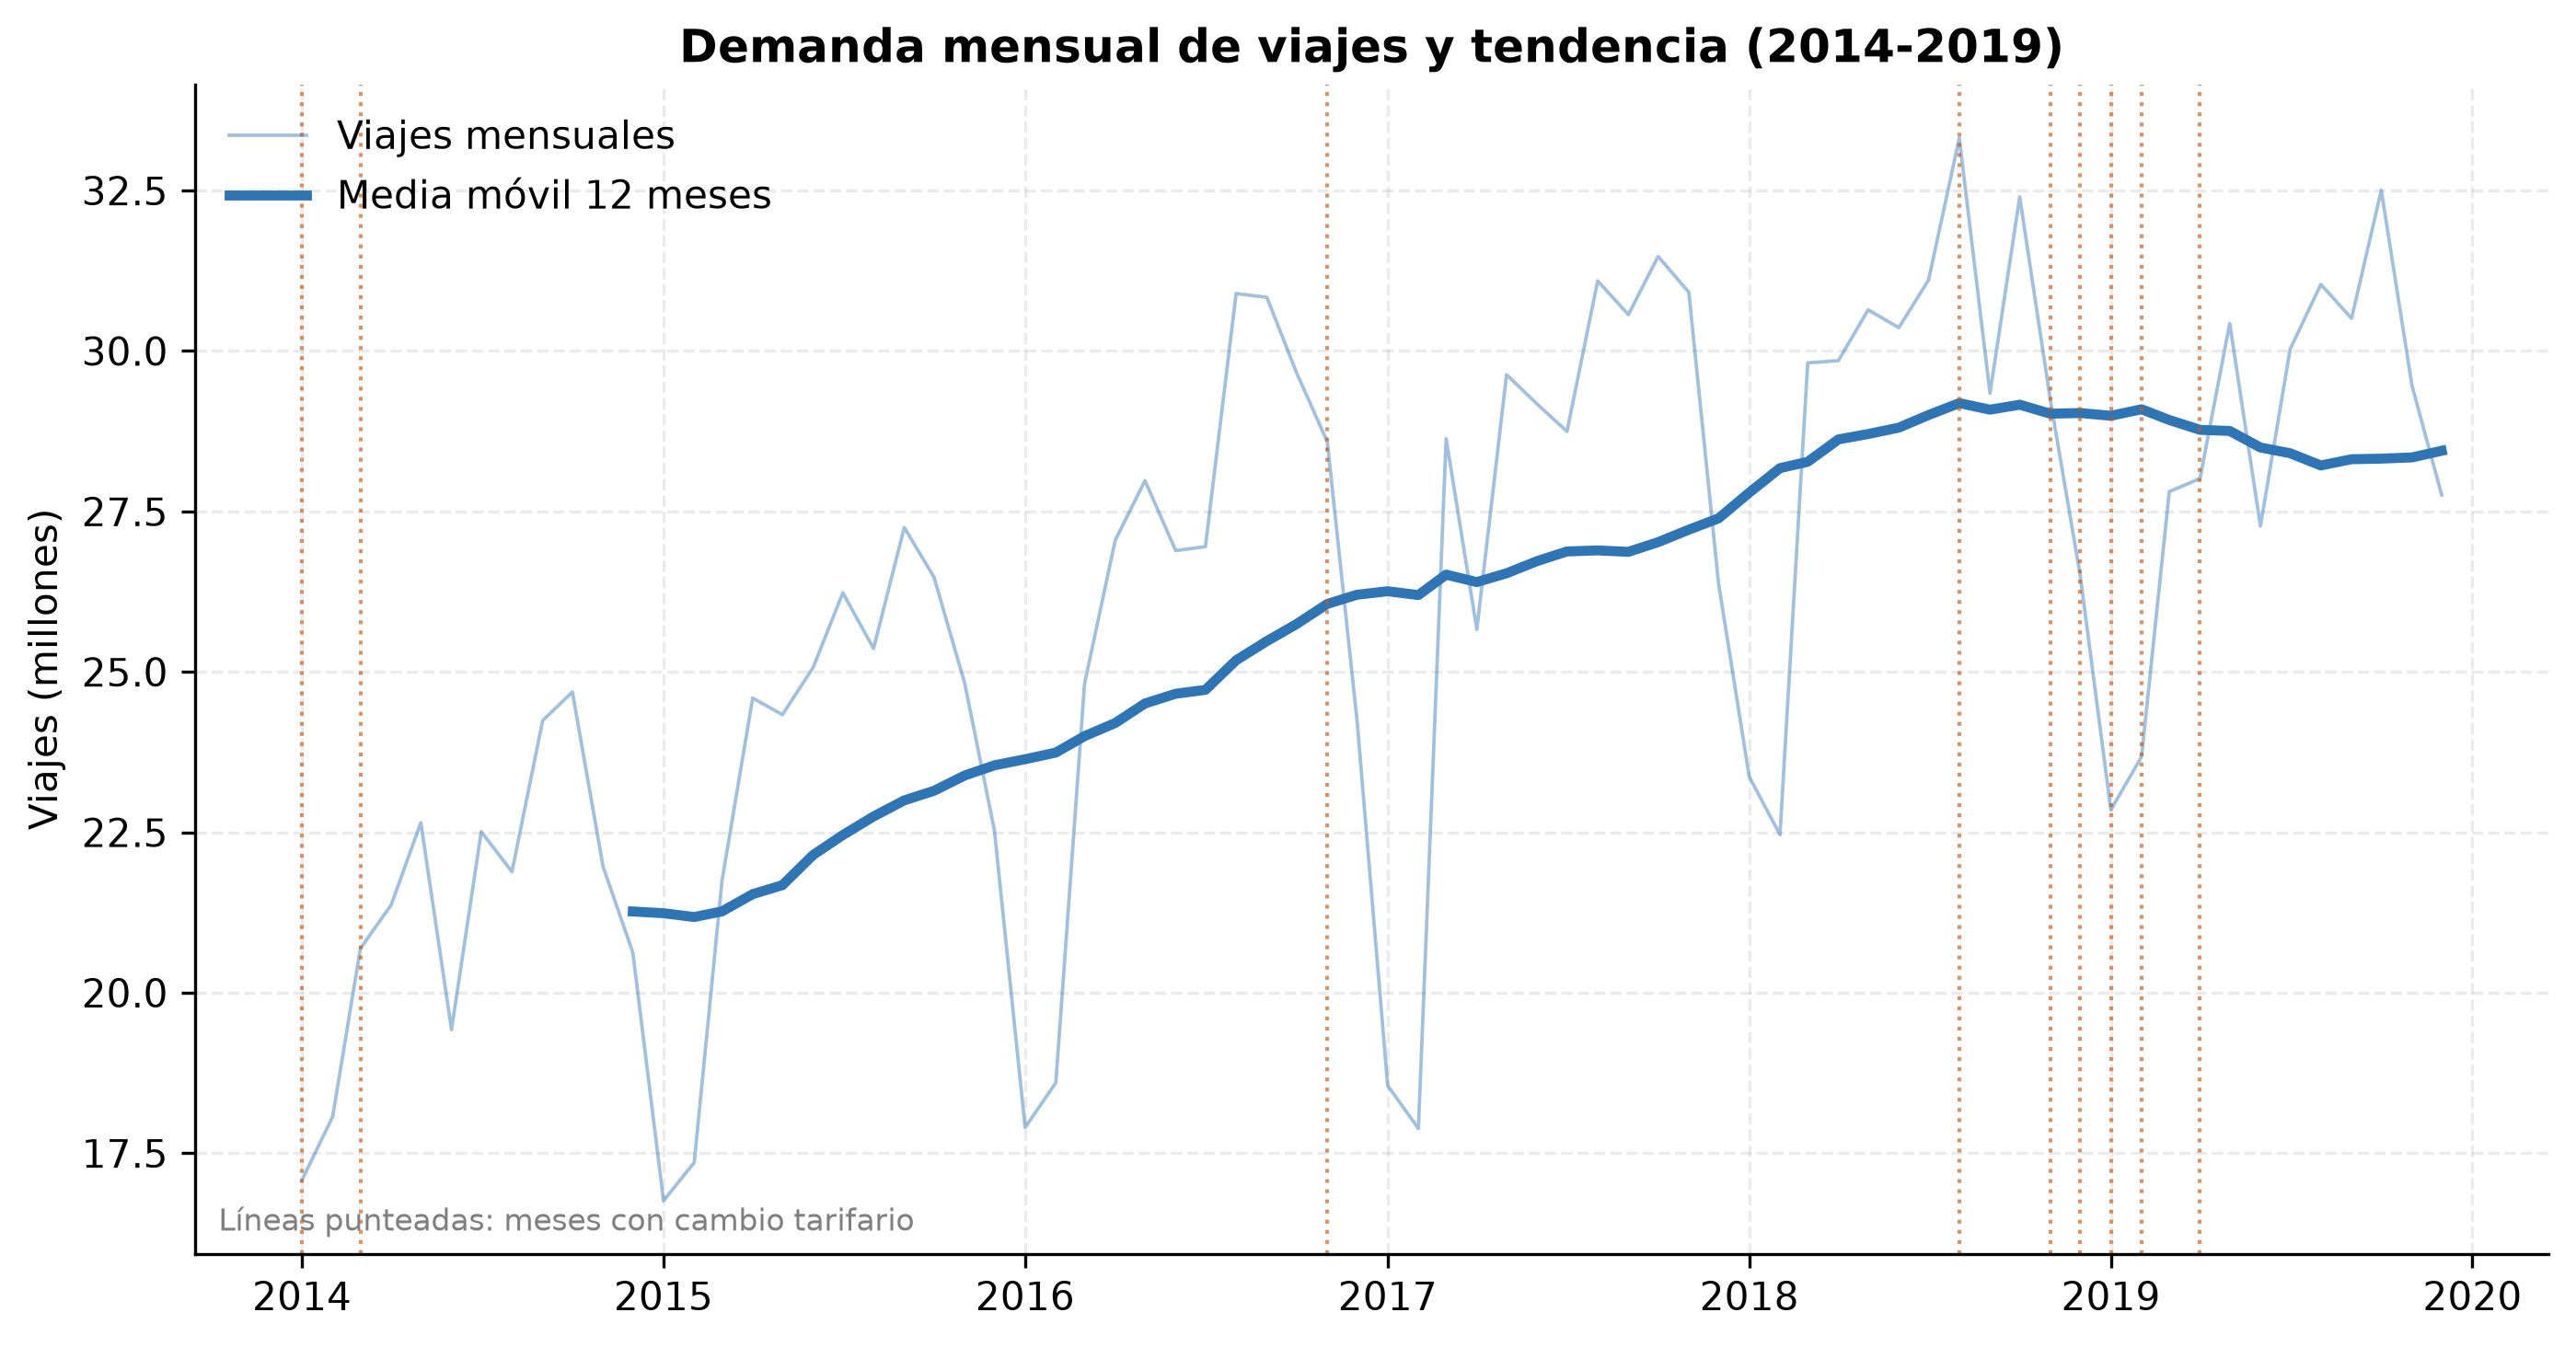

In [6]:
anual = datos["demanda_anual"].sort_values("anio").copy()
anual["crecimiento_pct"] = anual["viajes"].pct_change() * 100
tabla_anual = anual.copy()
tabla_anual["viajes"] = (tabla_anual["viajes"] / 1_000_000).round(1)
tabla_anual.columns = ["Año", "Viajes (millones)", "Variación interanual (%)"]
display(tabla_anual)

# Cobertura comparable: 2019 tiene 362 días con registro (faltan 30/04, 01/05 y 29/05).
promedio_diario = anual.set_index("anio")["viajes"] / datos["calidad"].set_index("anio")["fechas_distintas"]
print("Promedio diario de viajes (millones):")
print((promedio_diario / 1_000_000).round(3).to_string())
print("Variación del promedio diario 2018-2019:", f"{(promedio_diario.loc[2019]/promedio_diario.loc[2018]-1)*100:.1f}%")

display(Image(filename=str(FIG / "fig03_demanda_anual.png")))
display(Image(filename=str(FIG / "fig04_demanda_mensual.png")))

## 5. Líneas, estaciones y nuevos tramos

Se comparan los viajes anuales por línea y se separa el crecimiento de las estaciones que ya existían en 2014 del aporte de las estaciones incorporadas después. La línea H es el caso más destacado por la extensión de su traza.

,Línea,Viajes 2014 (mill.),Viajes 2019 (mill.),Crecimiento 2014-2019 (%),Participación 2019 (%)
0,A,48.100,63.500,31.900,18.600
1,B,71.600,87.400,22.200,25.600
2,C,41.500,50.700,22.100,14.800
3,D,68.200,80.900,18.700,23.700
4,E,18.400,24.100,31.200,7.100
5,H,7.500,34.700,364.600,10.200


,Línea,Estación,Primer año,Viajes 2014-2019 (mill.)
0,H,Córdoba,2015,8.100
1,H,Las Heras,2015,14.750
2,H,Santa Fe,2016,10.780
3,H,Facultad de Derecho,2018,3.030
4,E,Catalinas,2019,0.790
5,E,Correo Central,2019,1.120
6,E,Retiro,2019,0.860


,Línea,Estación,Viajes acumulados (mill.)
36,C,Constitución,131.500
42,C,Retiro,65.200
49,D,Congreso de Tucumán,61.400
48,D,Catedral,58.100
24,B,Federico Lacroze,50.300
32,B,Rosas,46.100
17,A,San Pedrito,46.000
26,B,Leandro N. Alem,44.500
21,B,Carlos Pellegrini,38.200
25,B,Florida,36.600


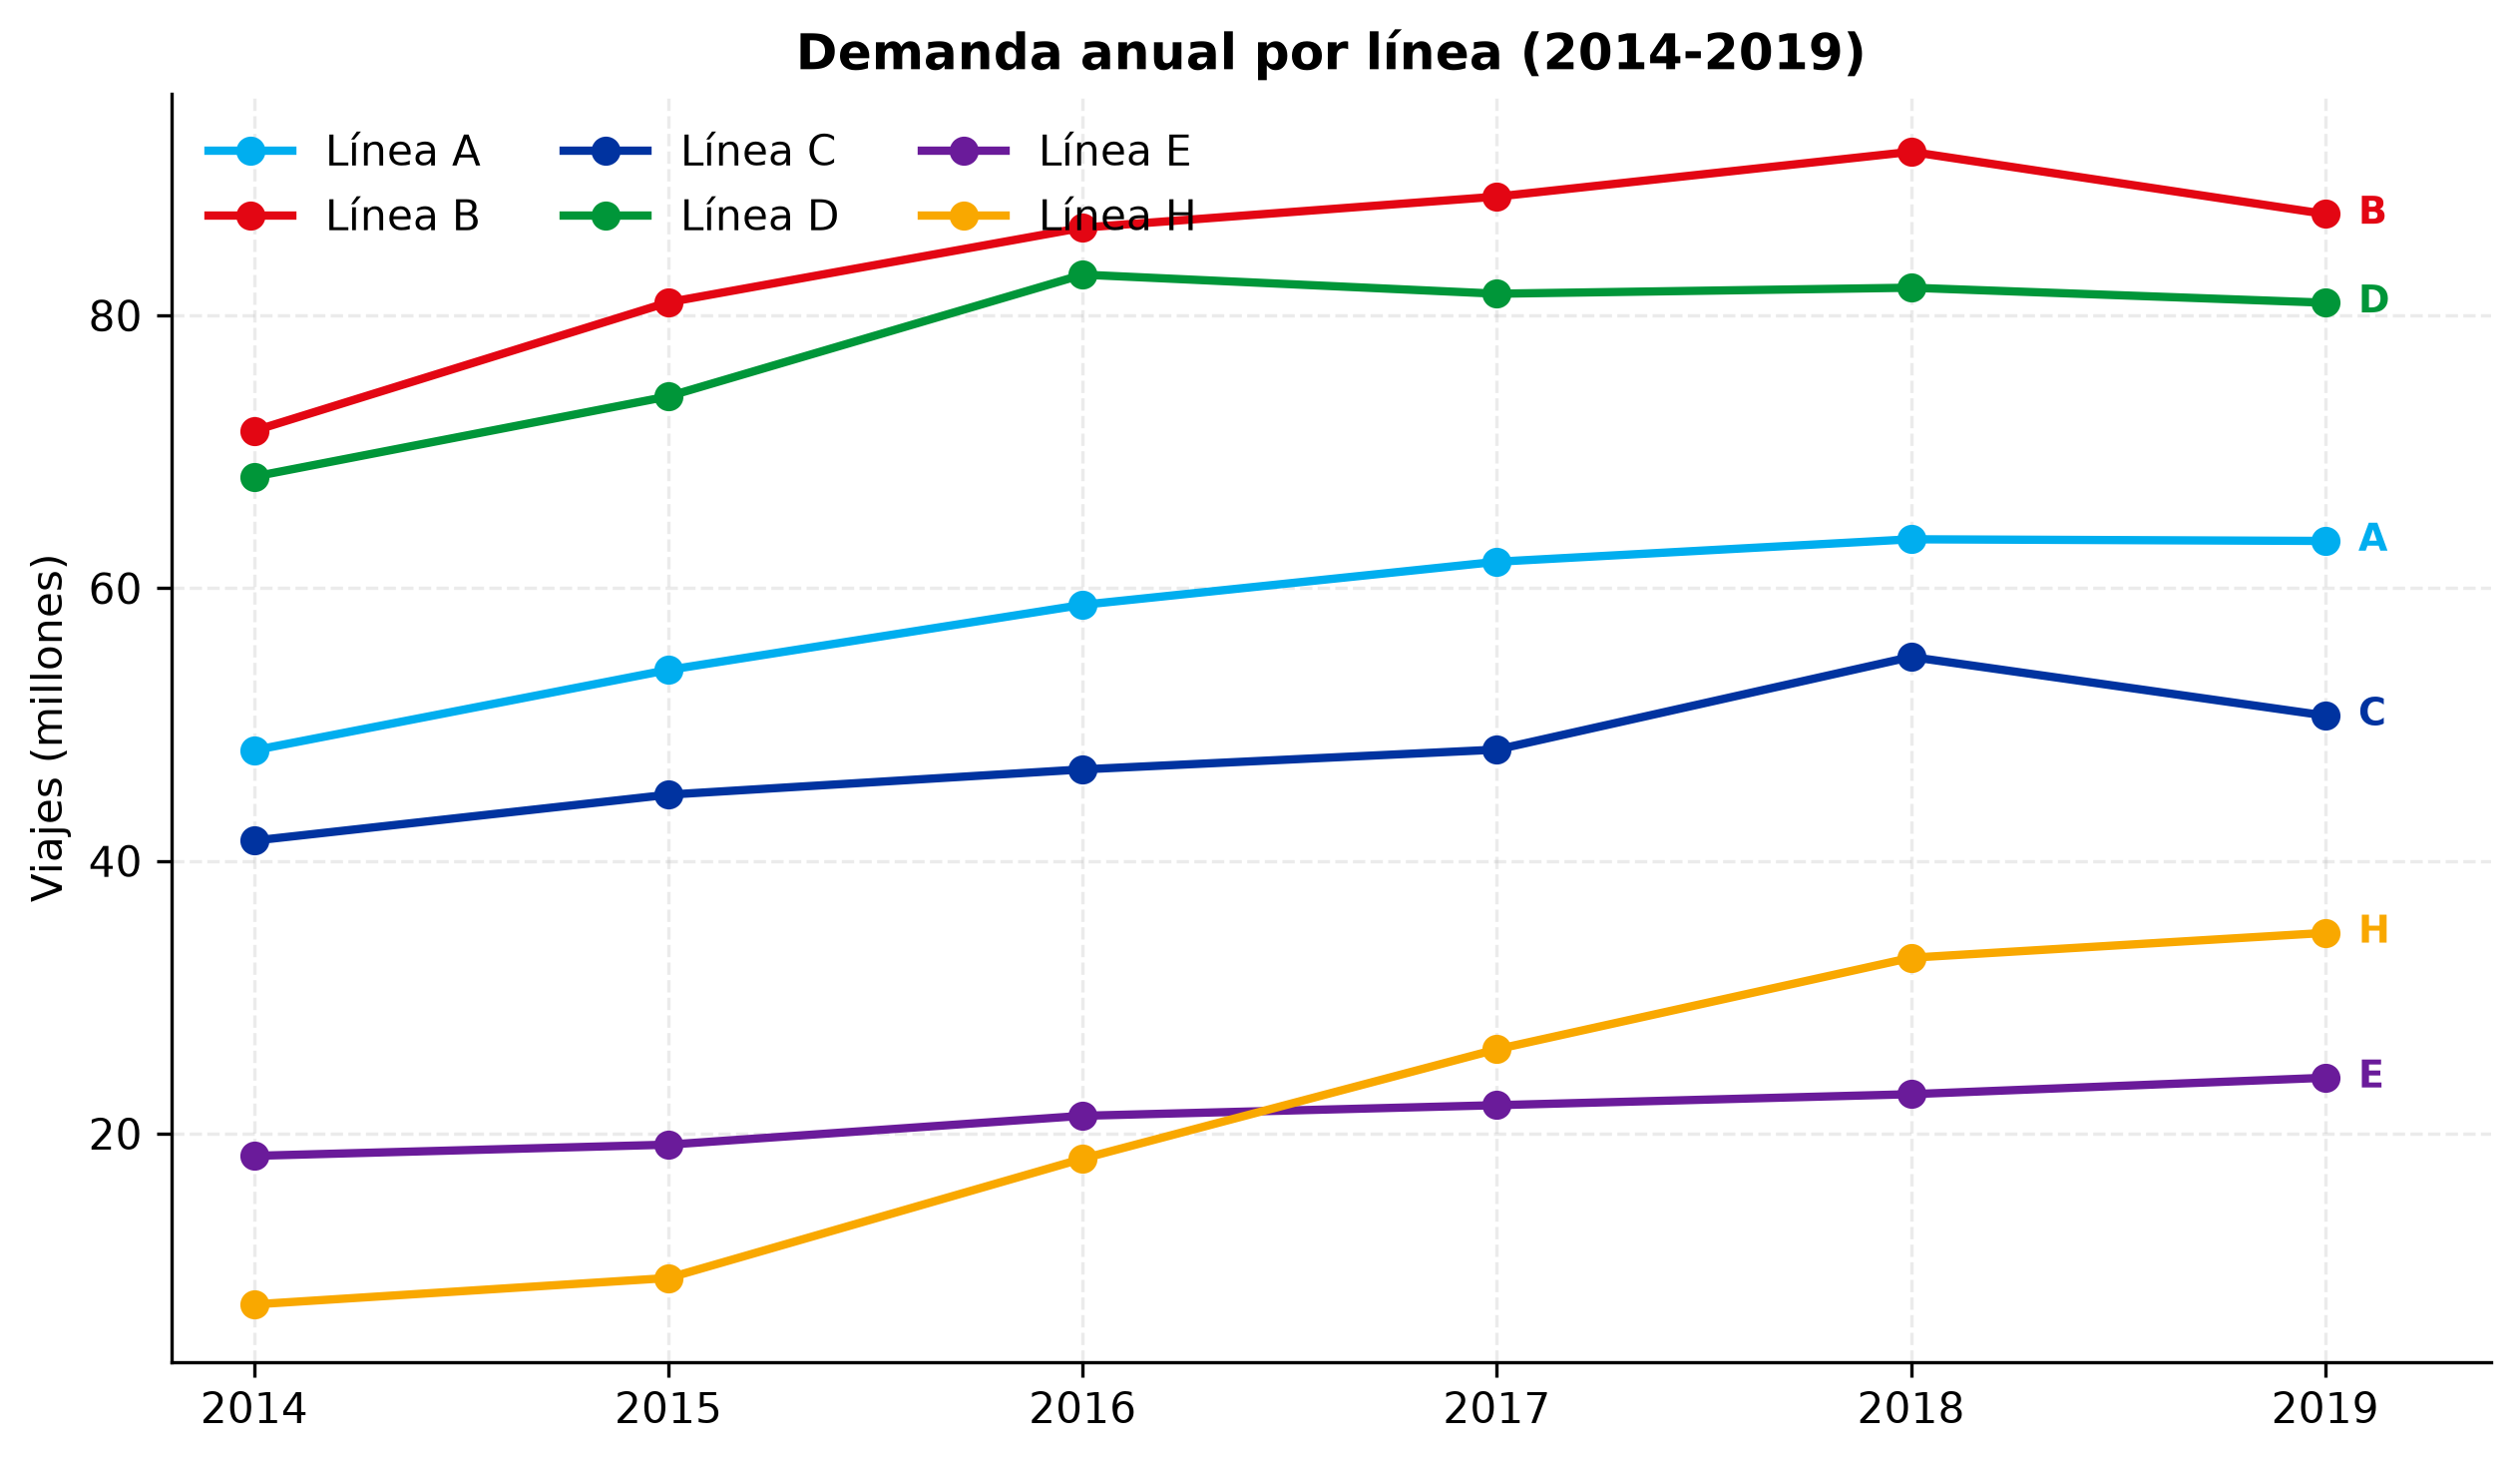

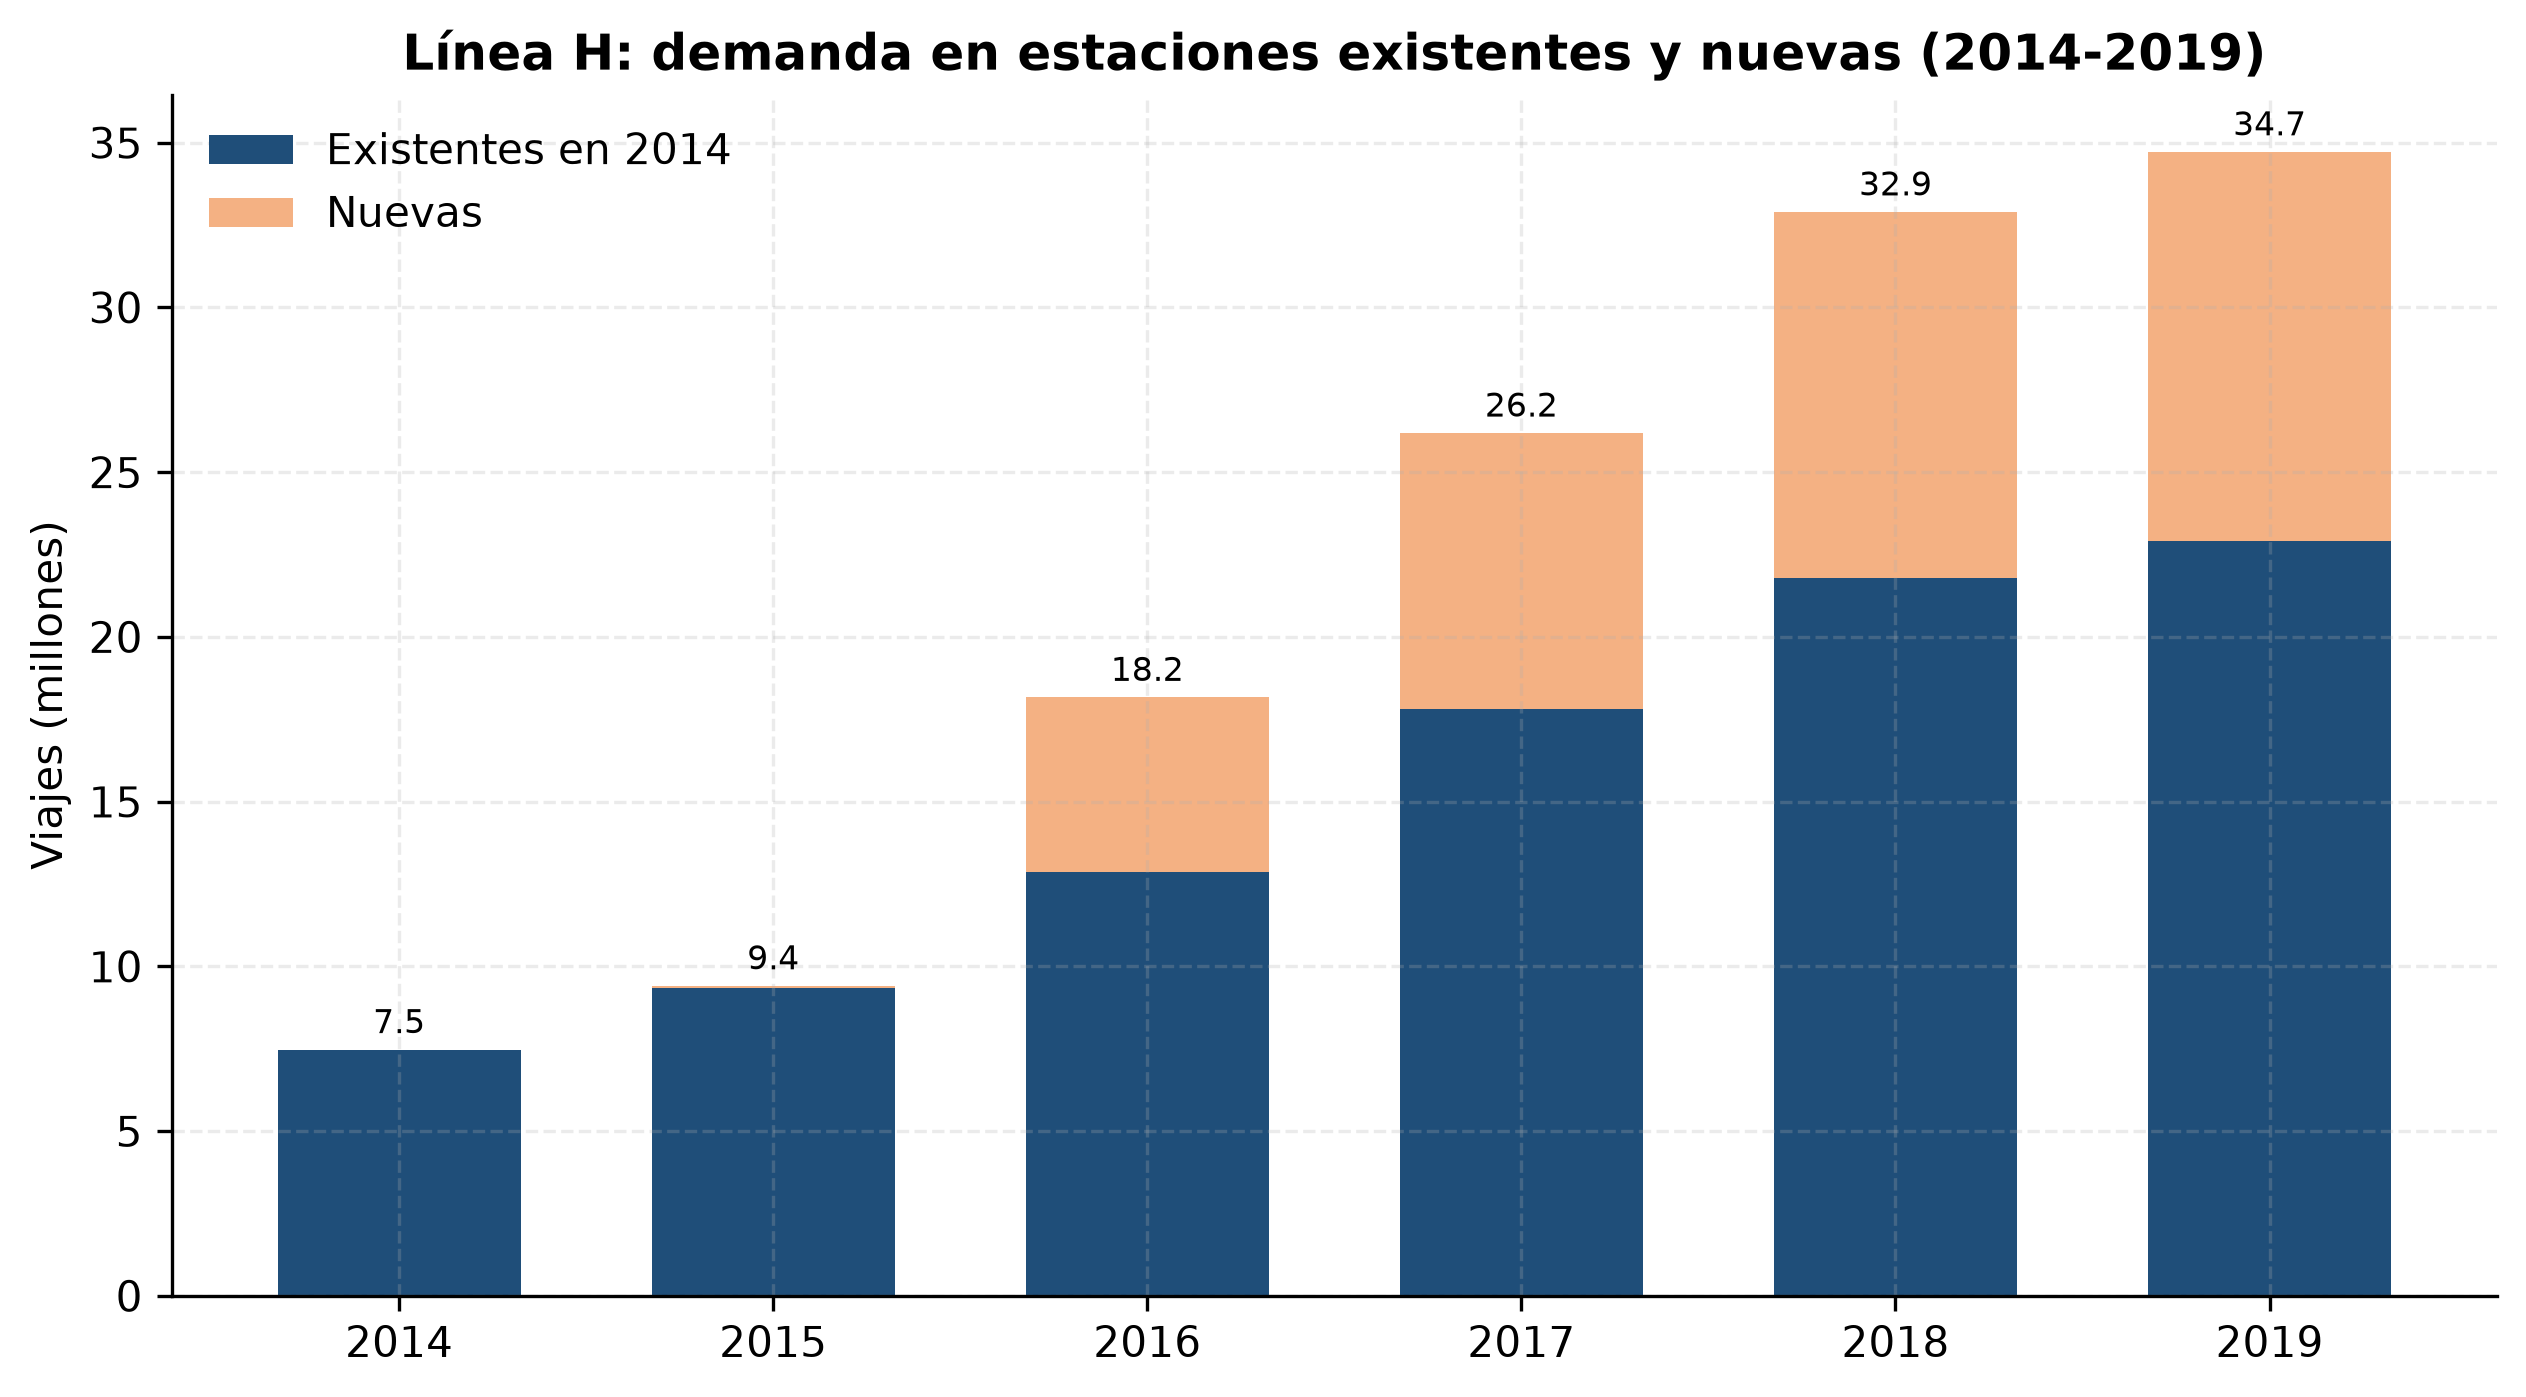

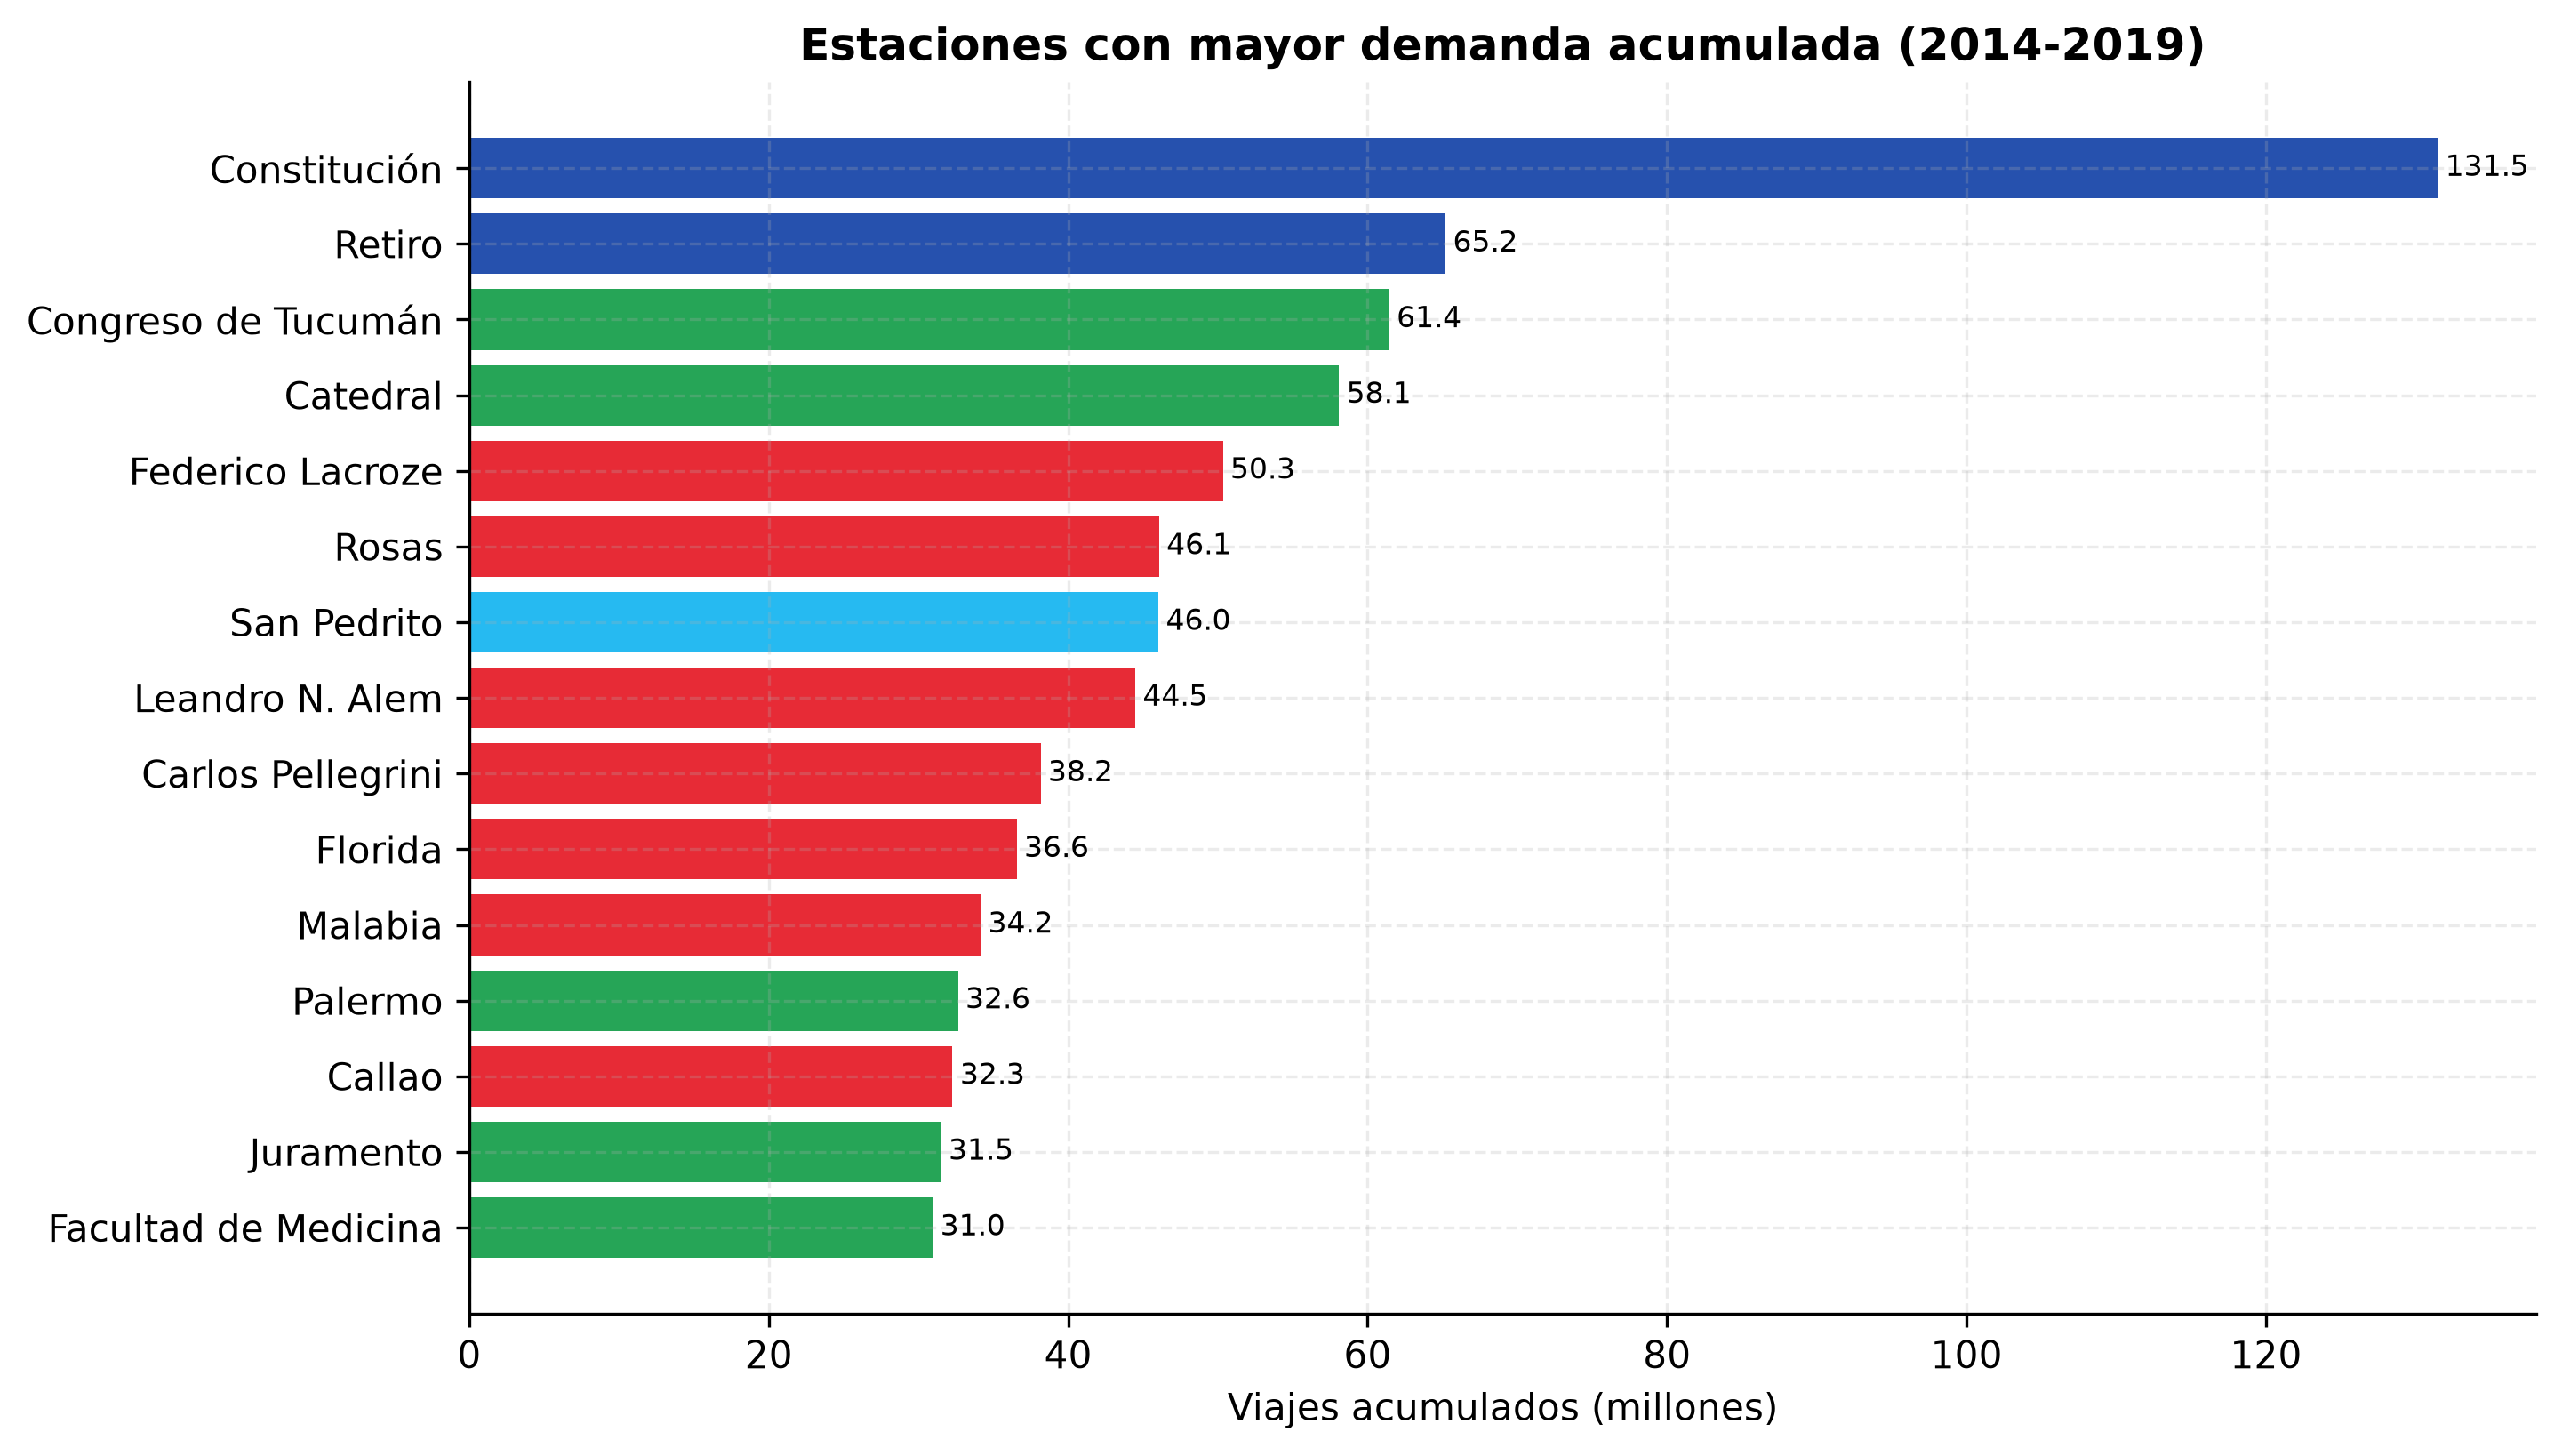

In [7]:
linea = datos["demanda_linea"]
piv = linea.pivot(index="anio", columns="linea", values="viajes")
tabla_linea = pd.DataFrame({
    "Línea": piv.columns,
    "Viajes 2014 (mill.)": (piv.loc[2014] / 1_000_000).round(1).values,
    "Viajes 2019 (mill.)": (piv.loc[2019] / 1_000_000).round(1).values,
    "Crecimiento 2014-2019 (%)": ((piv.loc[2019] / piv.loc[2014] - 1) * 100).round(1).values,
    "Participación 2019 (%)": (piv.loc[2019] / piv.loc[2019].sum() * 100).round(1).values,
})
display(tabla_linea)

nuevas = datos["nuevas"].copy()
nuevas["viajes_totales"] = (nuevas["viajes_totales"] / 1_000_000).round(2)
display(nuevas[["linea", "estacion_display", "primer_anio", "viajes_totales"]].rename(columns={
    "linea": "Línea", "estacion_display": "Estación", "primer_anio": "Primer año",
    "viajes_totales": "Viajes 2014-2019 (mill.)",
}))

top = datos["catalogo"].sort_values("viajes_totales", ascending=False).head(10).copy()
top["viajes_totales"] = (top["viajes_totales"] / 1_000_000).round(1)
display(top[["linea", "estacion_display", "viajes_totales"]].rename(columns={
    "linea": "Línea", "estacion_display": "Estación", "viajes_totales": "Viajes acumulados (mill.)",
}))

display(Image(filename=str(FIG / "fig05_demanda_lineas.png")))
display(Image(filename=str(FIG / "fig09_linea_h.png")))
display(Image(filename=str(FIG / "fig08_top_estaciones.png")))

## 6. Patrones temporales

El índice estacional compara cada mes con el promedio del año (100 = mes promedio). El perfil horario usa los registros de 2019 y distingue días hábiles de fin de semana.

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
anio,,,,,,,,,,,,
2014,80.000,85.000,97.000,100.000,107.000,91.000,106.000,103.000,114.000,116.000,103.000,97.000
2015,71.000,74.000,92.000,104.000,103.000,106.000,111.000,108.000,116.000,112.000,105.000,96.000
2016,68.000,71.000,95.000,103.000,107.000,103.000,103.000,118.000,118.000,113.000,109.000,93.000
2017,68.000,65.000,105.000,94.000,108.000,106.000,105.000,114.000,112.000,115.000,113.000,96.000
2018,80.000,77.000,103.000,103.000,106.000,105.000,107.000,115.000,101.000,112.000,101.000,91.000
2019,80.000,83.000,98.000,98.000,107.000,96.000,106.000,109.000,107.000,114.000,104.000,98.000


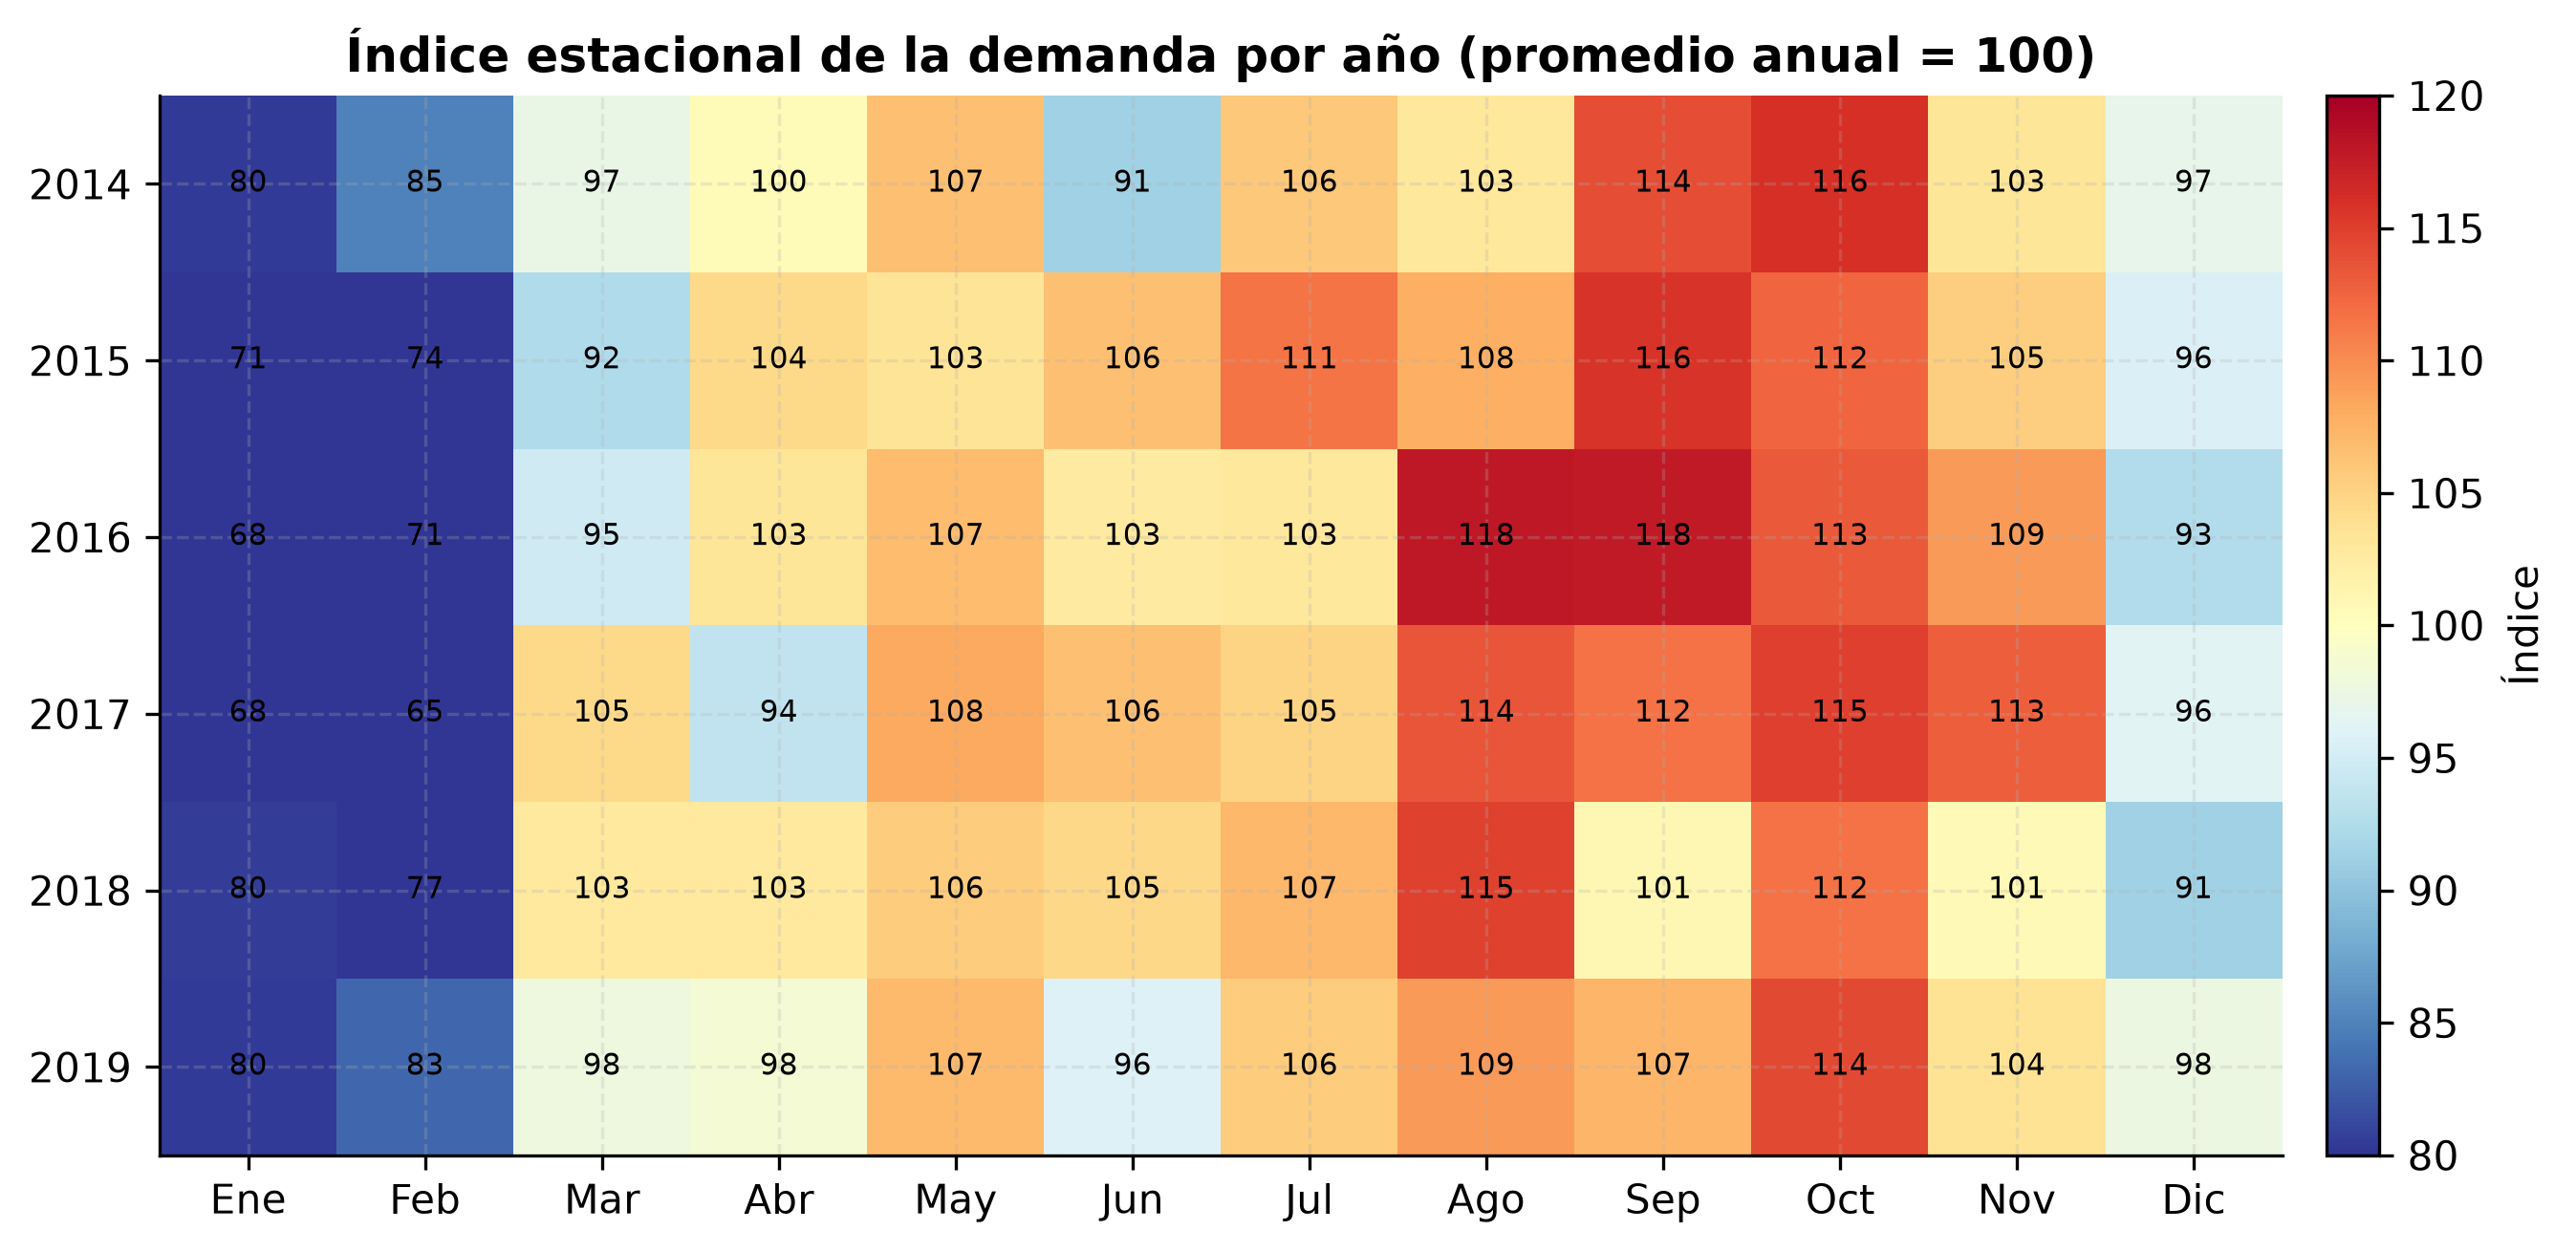

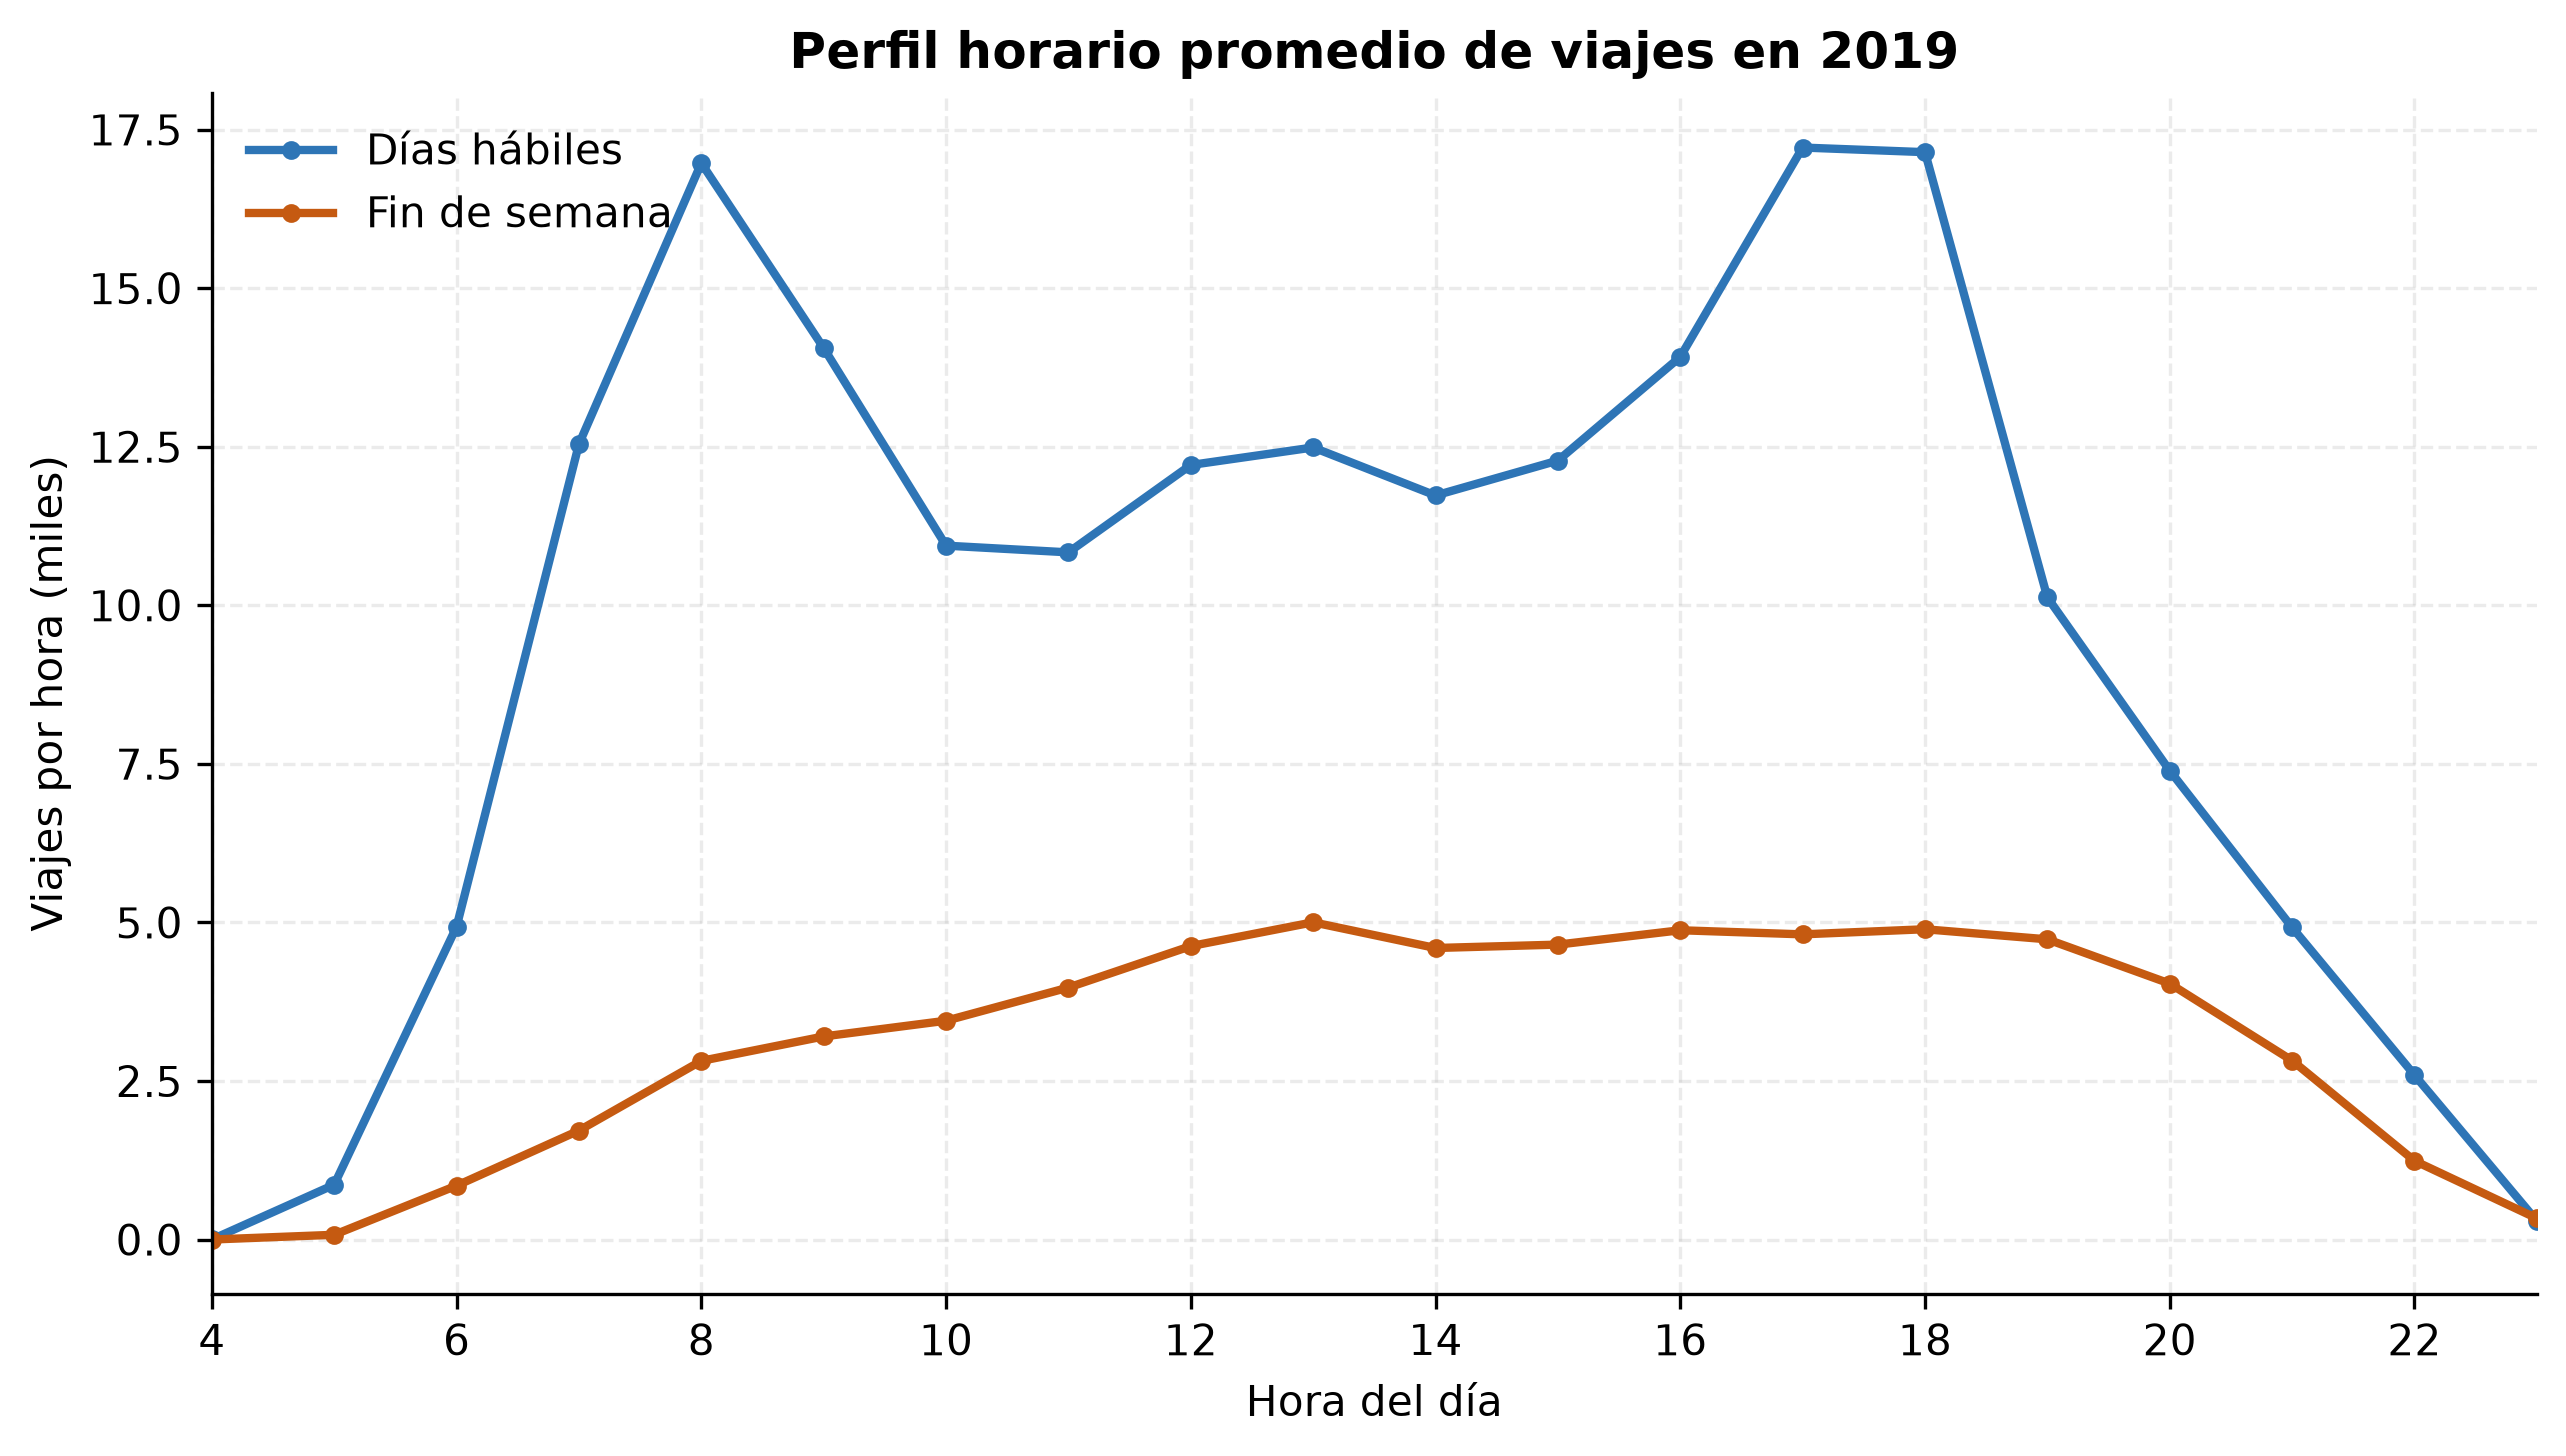

In [7]:
mensual = datos["demanda_mensual"].copy()
mensual["anio"] = mensual["fecha"].dt.year
mensual["mes"] = mensual["fecha"].dt.month
piv_mes = mensual.pivot(index="anio", columns="mes", values="viajes")
indice = piv_mes.div(piv_mes.mean(axis=1), axis=0) * 100
indice.columns = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
display(indice.round(0))

display(Image(filename=str(FIG / "fig06_estacionalidad.png")))
display(Image(filename=str(FIG / "fig07_perfil_horario.png")))

## 7. Relación tarifa-demanda y elasticidad

Se estima un modelo log-log mensual:

$$\ln(Q_t) = \alpha + \beta \ln(P_t^{real}) + \gamma t + \delta_m + \varepsilon_t$$

donde $Q_t$ son los viajes, $P_t^{real}$ es la tarifa real, $t$ una tendencia lineal y $\delta_m$ dummies mensuales. Los errores estándar son HAC (Newey-West, 3 rezagos). $\beta$ se interpreta como elasticidad-precio de la demanda. La estimación es exploratoria y no causal.

Correlación entre variación interanual de la demanda y de la tarifa real:
  rezago 0: -0.568
  rezago 1: -0.598
  rezago 2: -0.537
  rezago 3: -0.395


,Modelo,Elasticidad,IC 95% inferior,IC 95% superior,p-valor,R²,N
0,Log-log + tendencia + dummies mensuales,-0.168,-0.220,-0.116,0.000,0.937,64


Lectura: un aumento de 10% en la tarifa real se asocia con una caída de aproximadamente 1.68% en los viajes, manteniendo tendencia y estacionalidad.


,Línea,Elasticidad,IC 95% inferior,IC 95% superior,p-valor,R²,N
0,A,-0.182,-0.233,-0.130,0.000,0.937,64
1,B,-0.171,-0.240,-0.102,0.000,0.875,64
2,C,-0.137,-0.306,0.033,0.115,0.574,64
3,D,-0.192,-0.257,-0.127,0.000,0.939,64
4,E,-0.175,-0.245,-0.105,0.000,0.938,64
5,H,-0.387,-0.577,-0.196,0.000,0.962,64


,Modelo,Muestra,Índice de precios,Elasticidad,IC 95% inferior,IC 95% superior,p-valor,R²,N
0,Principal: real + tendencia,2014-01 a 2019-04,IPC CABA,-0.168,-0.220,-0.116,0.000,0.937,64
1,Sin tendencia lineal,2014-01 a 2019-04,IPC CABA,-0.366,-0.583,-0.149,0.001,0.683,64
2,Con meses atípicos,2014-01 a 2019-04,IPC CABA,-0.152,-0.207,-0.098,0.000,0.939,64
3,Tarifa nominal,2014-01 a 2019-04,Nominal,-0.157,-0.208,-0.106,0.000,0.938,64
4,Submuestra CABA,2017-01 a 2019-04,IPC CABA,-0.201,-0.315,-0.087,0.001,0.928,28
5,Submuestra nacional,2017-01 a 2019-04,IPC nacional,-0.202,-0.320,-0.085,0.001,0.926,28


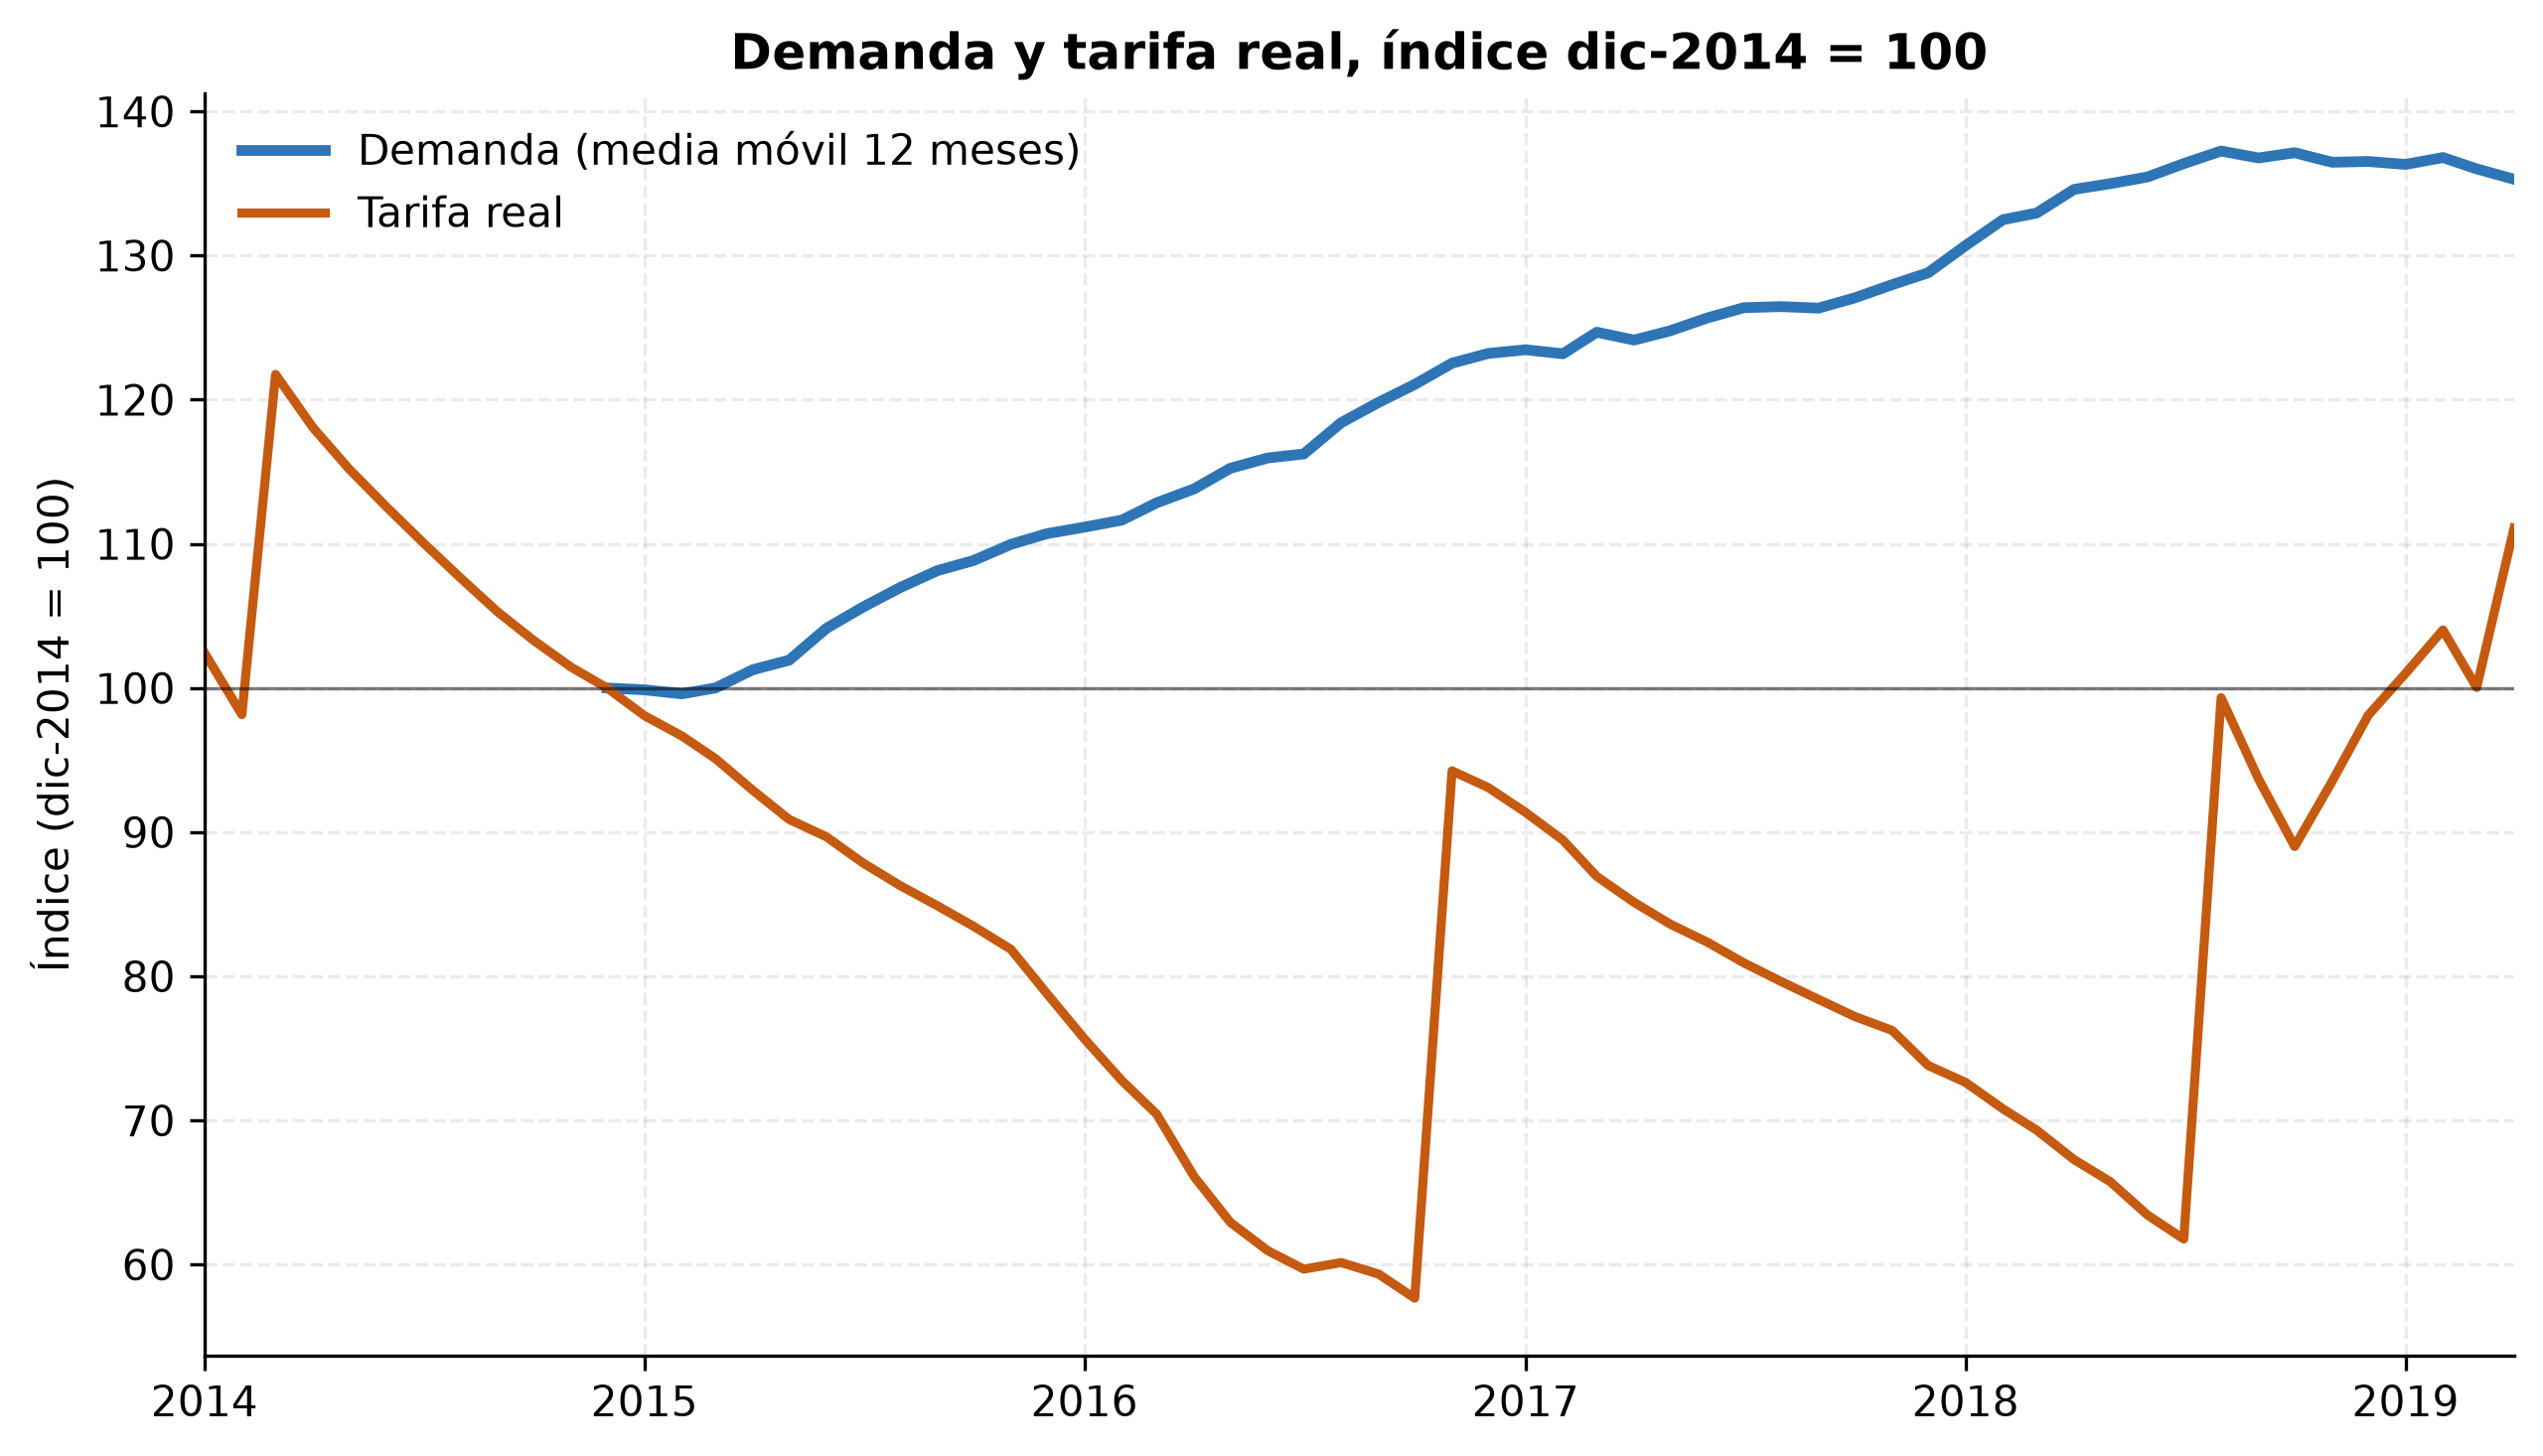

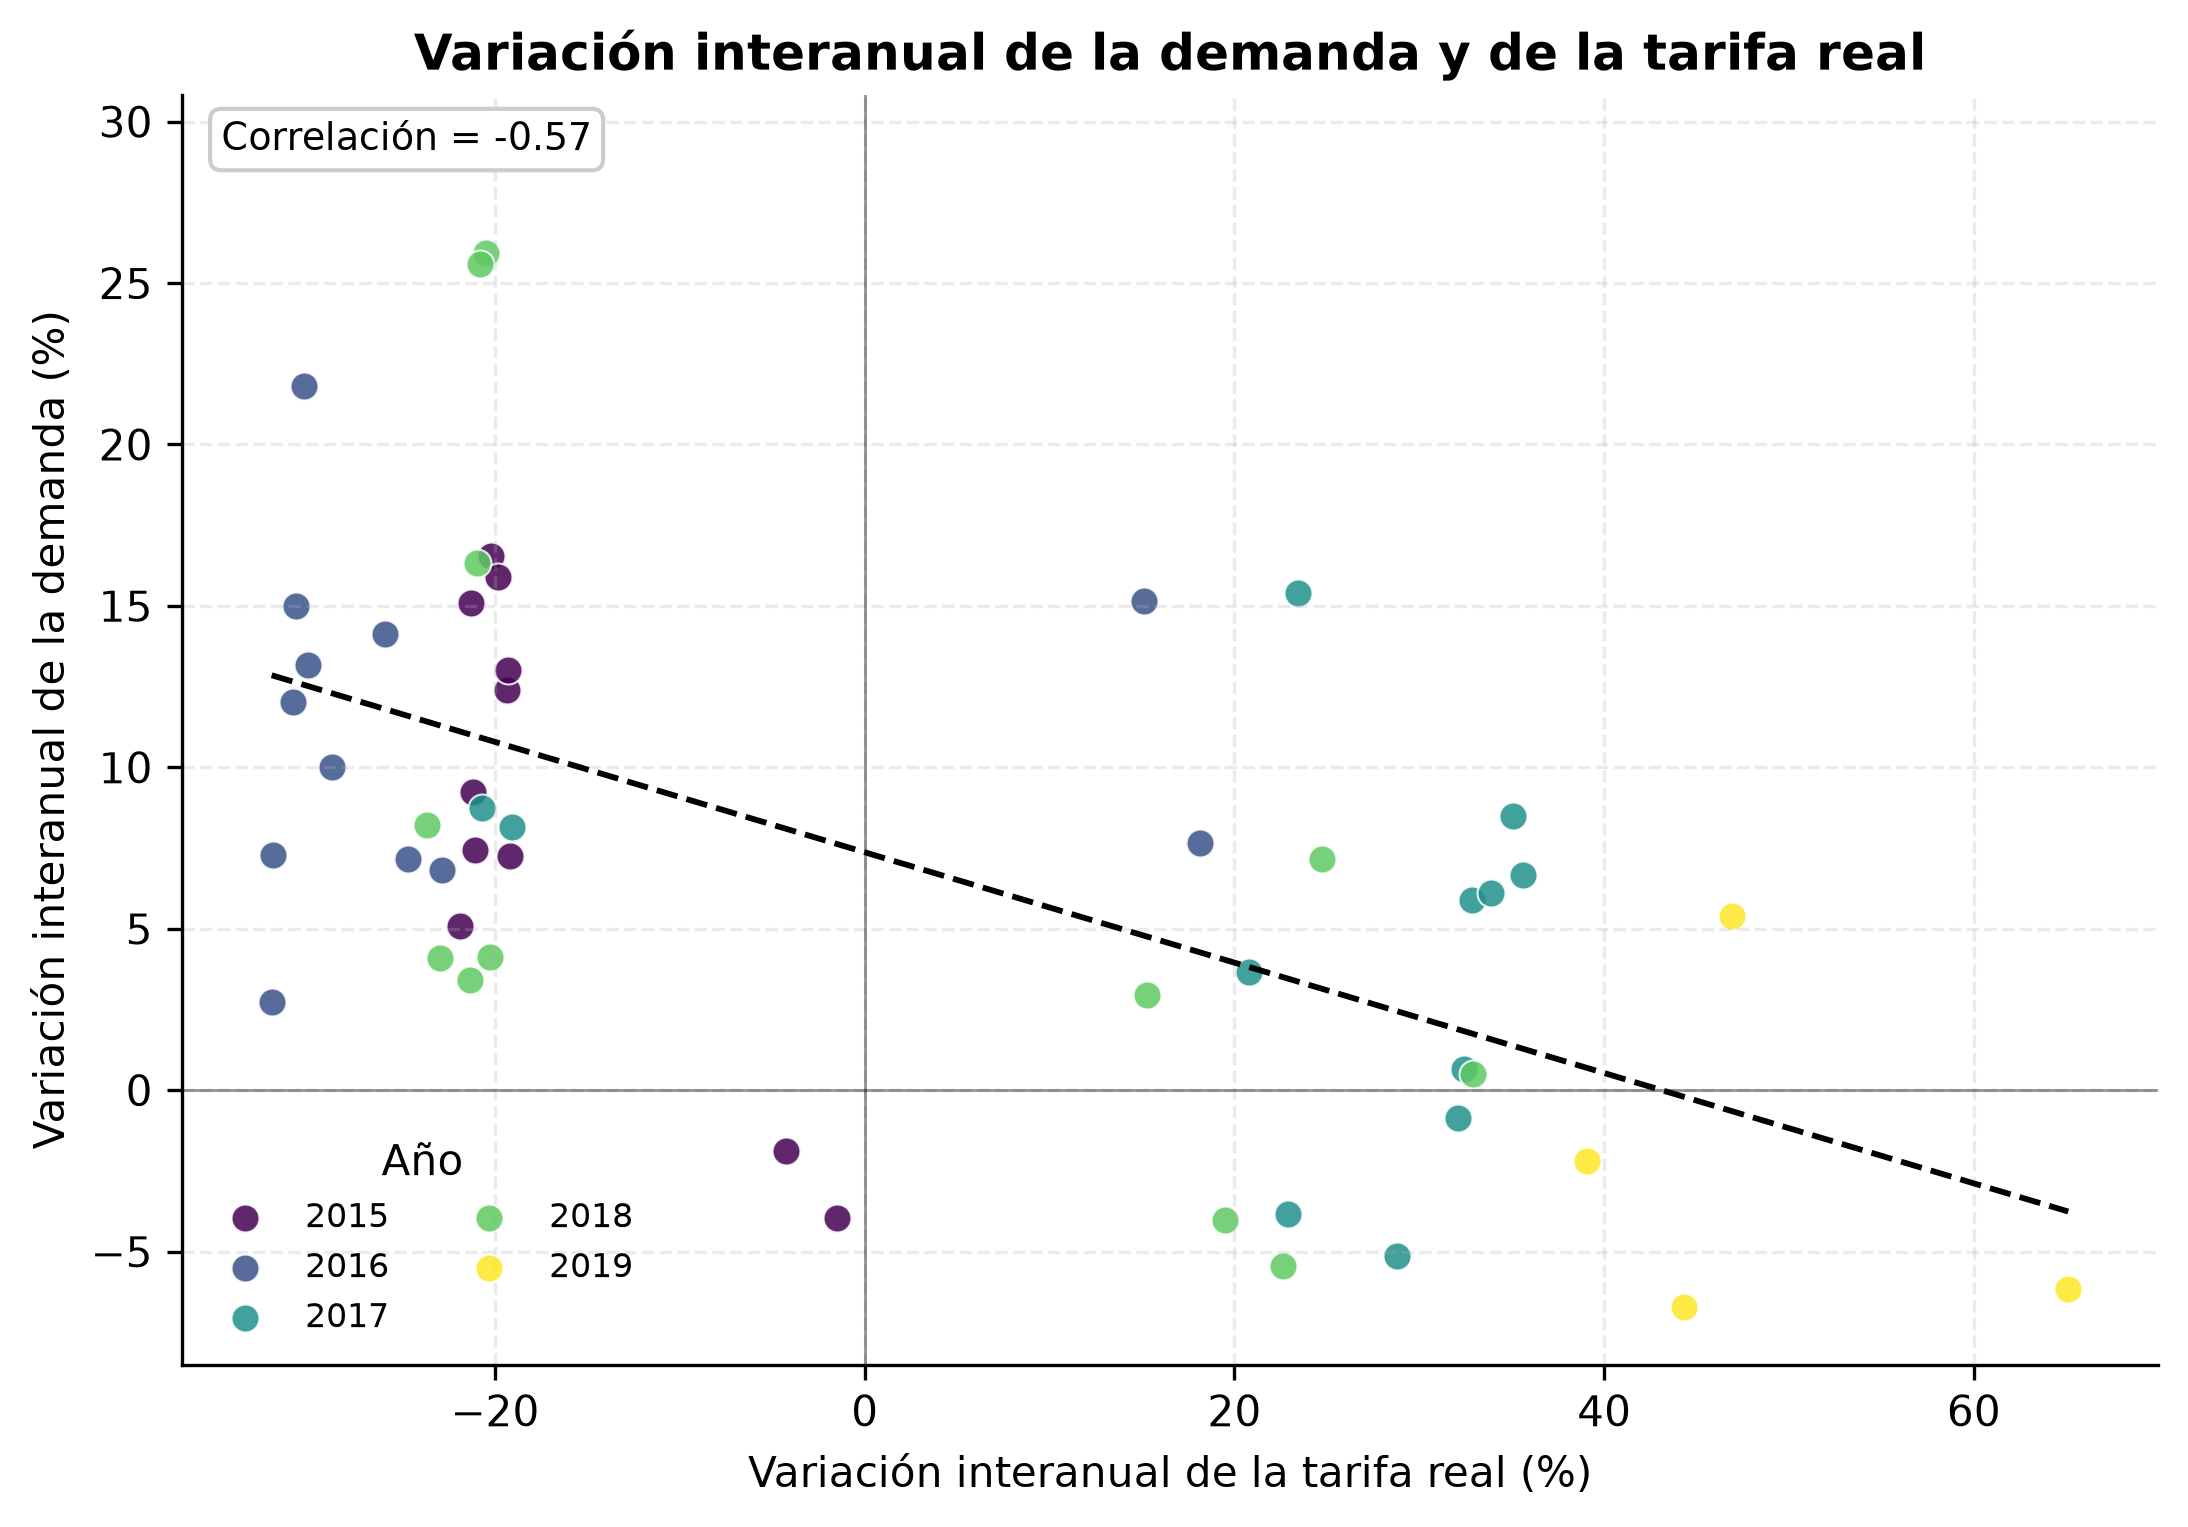

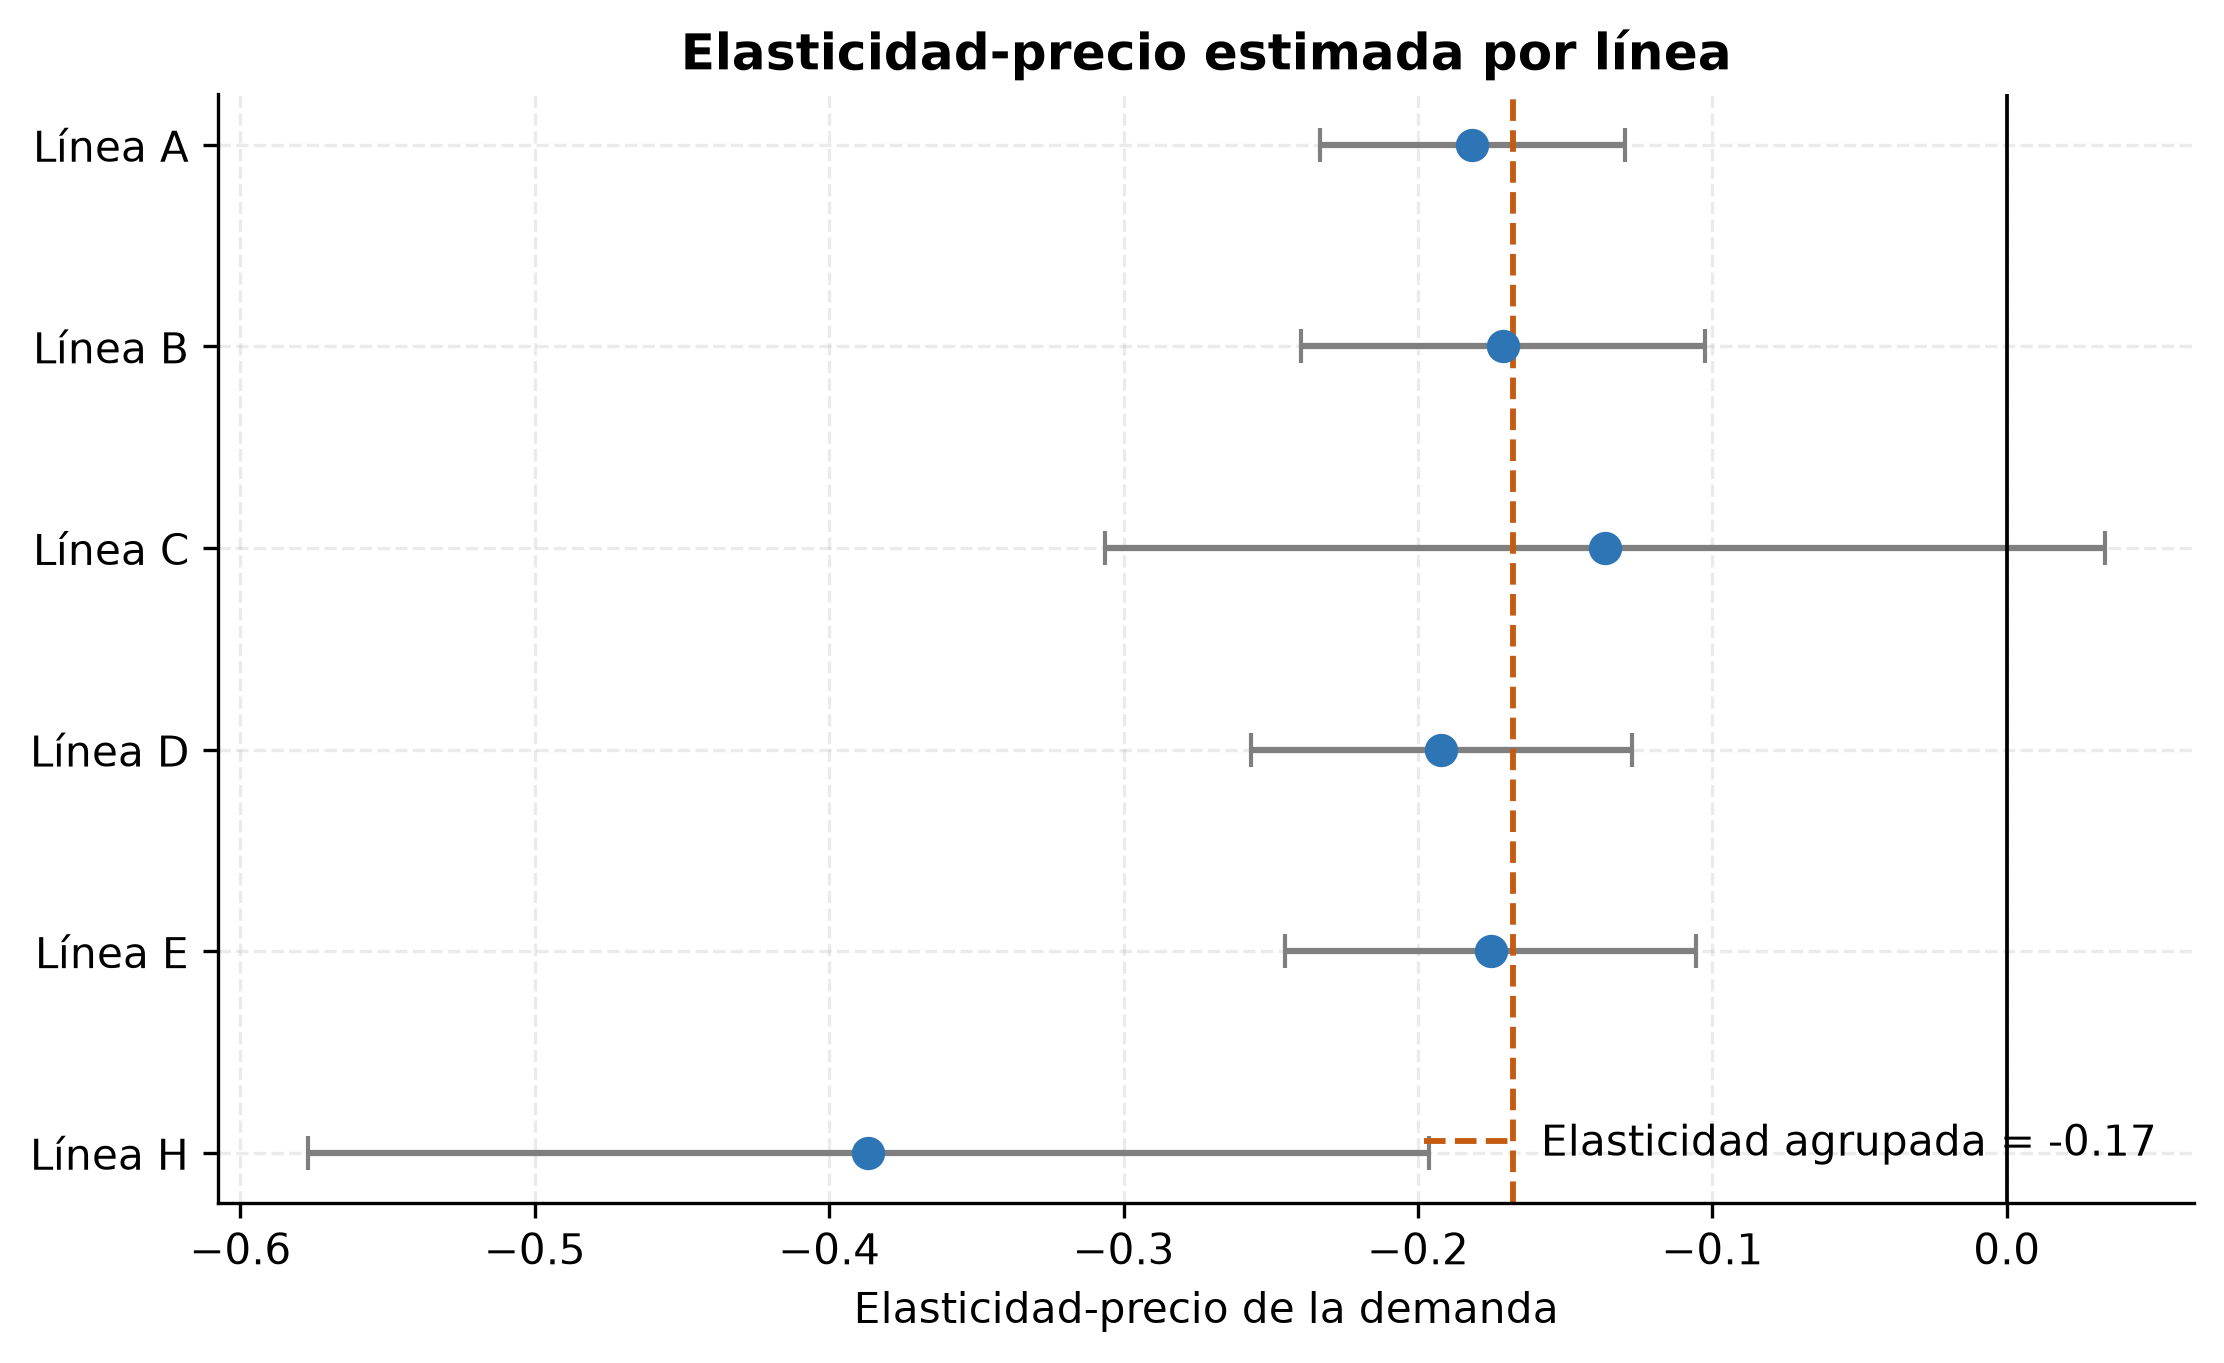

In [8]:
panel = datos["panel"].sort_values("fecha").copy()
panel = panel[panel["fecha"] <= "2019-04-01"].copy()
panel["viajes_yoy"] = panel["viajes_total"].pct_change(12) * 100
panel["precio_real_yoy"] = panel["precio_real"].pct_change(12) * 100

corr = panel.dropna(subset=["viajes_yoy", "precio_real_yoy"])
print("Correlación entre variación interanual de la demanda y de la tarifa real:")
for lag in range(4):
    valor = corr["viajes_yoy"].corr(corr["precio_real_yoy"].shift(lag))
    print(f"  rezago {lag}: {valor:.3f}")

d = panel.dropna(subset=["precio_real", "viajes_total"]).copy()
d["log_viajes"] = np.log(d["viajes_total"])
d["log_precio_real"] = np.log(d["precio_real"])
d["tendencia"] = np.arange(len(d))
d["mes_cat"] = d["mes"].astype(str)

modelo = smf.ols(
    "log_viajes ~ log_precio_real + tendencia + C(mes_cat)", data=d
).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
ci = modelo.conf_int().loc["log_precio_real"].tolist()
tabla_modelo = pd.DataFrame([{
    "Modelo": "Log-log + tendencia + dummies mensuales",
    "Elasticidad": modelo.params["log_precio_real"],
    "IC 95% inferior": ci[0],
    "IC 95% superior": ci[1],
    "p-valor": modelo.pvalues["log_precio_real"],
    "R²": modelo.rsquared,
    "N": int(modelo.nobs),
}])
display(tabla_modelo.round(3))
print("Lectura: un aumento de 10% en la tarifa real se asocia con una caída de aproximadamente "
      f"{abs(modelo.params['log_precio_real'])*10:.2f}% en los viajes, manteniendo tendencia y estacionalidad.")

filas = []
for lin in sorted(datos["panel_linea"]["linea"].unique()):
    dl = datos["panel_linea"][
        (datos["panel_linea"]["linea"] == lin)
        & (datos["panel_linea"]["fecha"] <= "2019-04-01")
    ].dropna(subset=["precio_real", "viajes"]).copy()
    dl["log_viajes"] = np.log(dl["viajes"])
    dl["log_precio_real"] = np.log(dl["precio_real"])
    dl["tendencia"] = np.arange(len(dl))
    dl["mes_cat"] = dl["mes"].astype(str)
    m = smf.ols("log_viajes ~ log_precio_real + tendencia + C(mes_cat)", data=dl).fit(
        cov_type="HAC", cov_kwds={"maxlags": 3}
    )
    ci_l = m.conf_int().loc["log_precio_real"].tolist()
    filas.append({
        "Línea": lin,
        "Elasticidad": m.params["log_precio_real"],
        "IC 95% inferior": ci_l[0],
        "IC 95% superior": ci_l[1],
        "p-valor": m.pvalues["log_precio_real"],
        "R²": m.rsquared,
        "N": int(m.nobs),
    })
display(pd.DataFrame(filas).round(3))

robustez = TAB / "tabla_robustez_elasticidad.csv"
if robustez.exists():
    display(pd.read_csv(robustez, encoding="utf-8-sig").round(3))
else:
    print("Para ver la tabla de robustez, ejecutar src/03_robustez.py")

display(Image(filename=str(FIG / "fig10_demanda_vs_tarifa.png")))
display(Image(filename=str(FIG / "fig11_dispersion_yoy.png")))
display(Image(filename=str(FIG / "fig12_elasticidad_lineas.png")))

## 8. Ingresos estimados

Se multiplican los viajes mensuales por la tarifa nominal vigente. Es una estimación analítica: no incorpora descuentos, franquicias, pases ni evasión, por lo que no equivale a la recaudación efectiva.

,Año,Viajes (mill.),Ingreso nominal (miles de millones $),Ingreso real (miles de millones $ dic-2016),Meses
0,2014,255.200,1.110,2.220,12
1,2015,282.500,1.270,2.010,12
2,2016,314.400,1.570,1.740,12
3,2017,328.700,2.470,2.160,12
4,2018,348.400,3.450,2.220,12
5,2019,102.300,1.740,0.860,4


Variación 2014-2018 del ingreso nominal: 209.8%
Variación 2014-2018 del ingreso real: -0.3%
2019 corresponde solo a enero-abril.


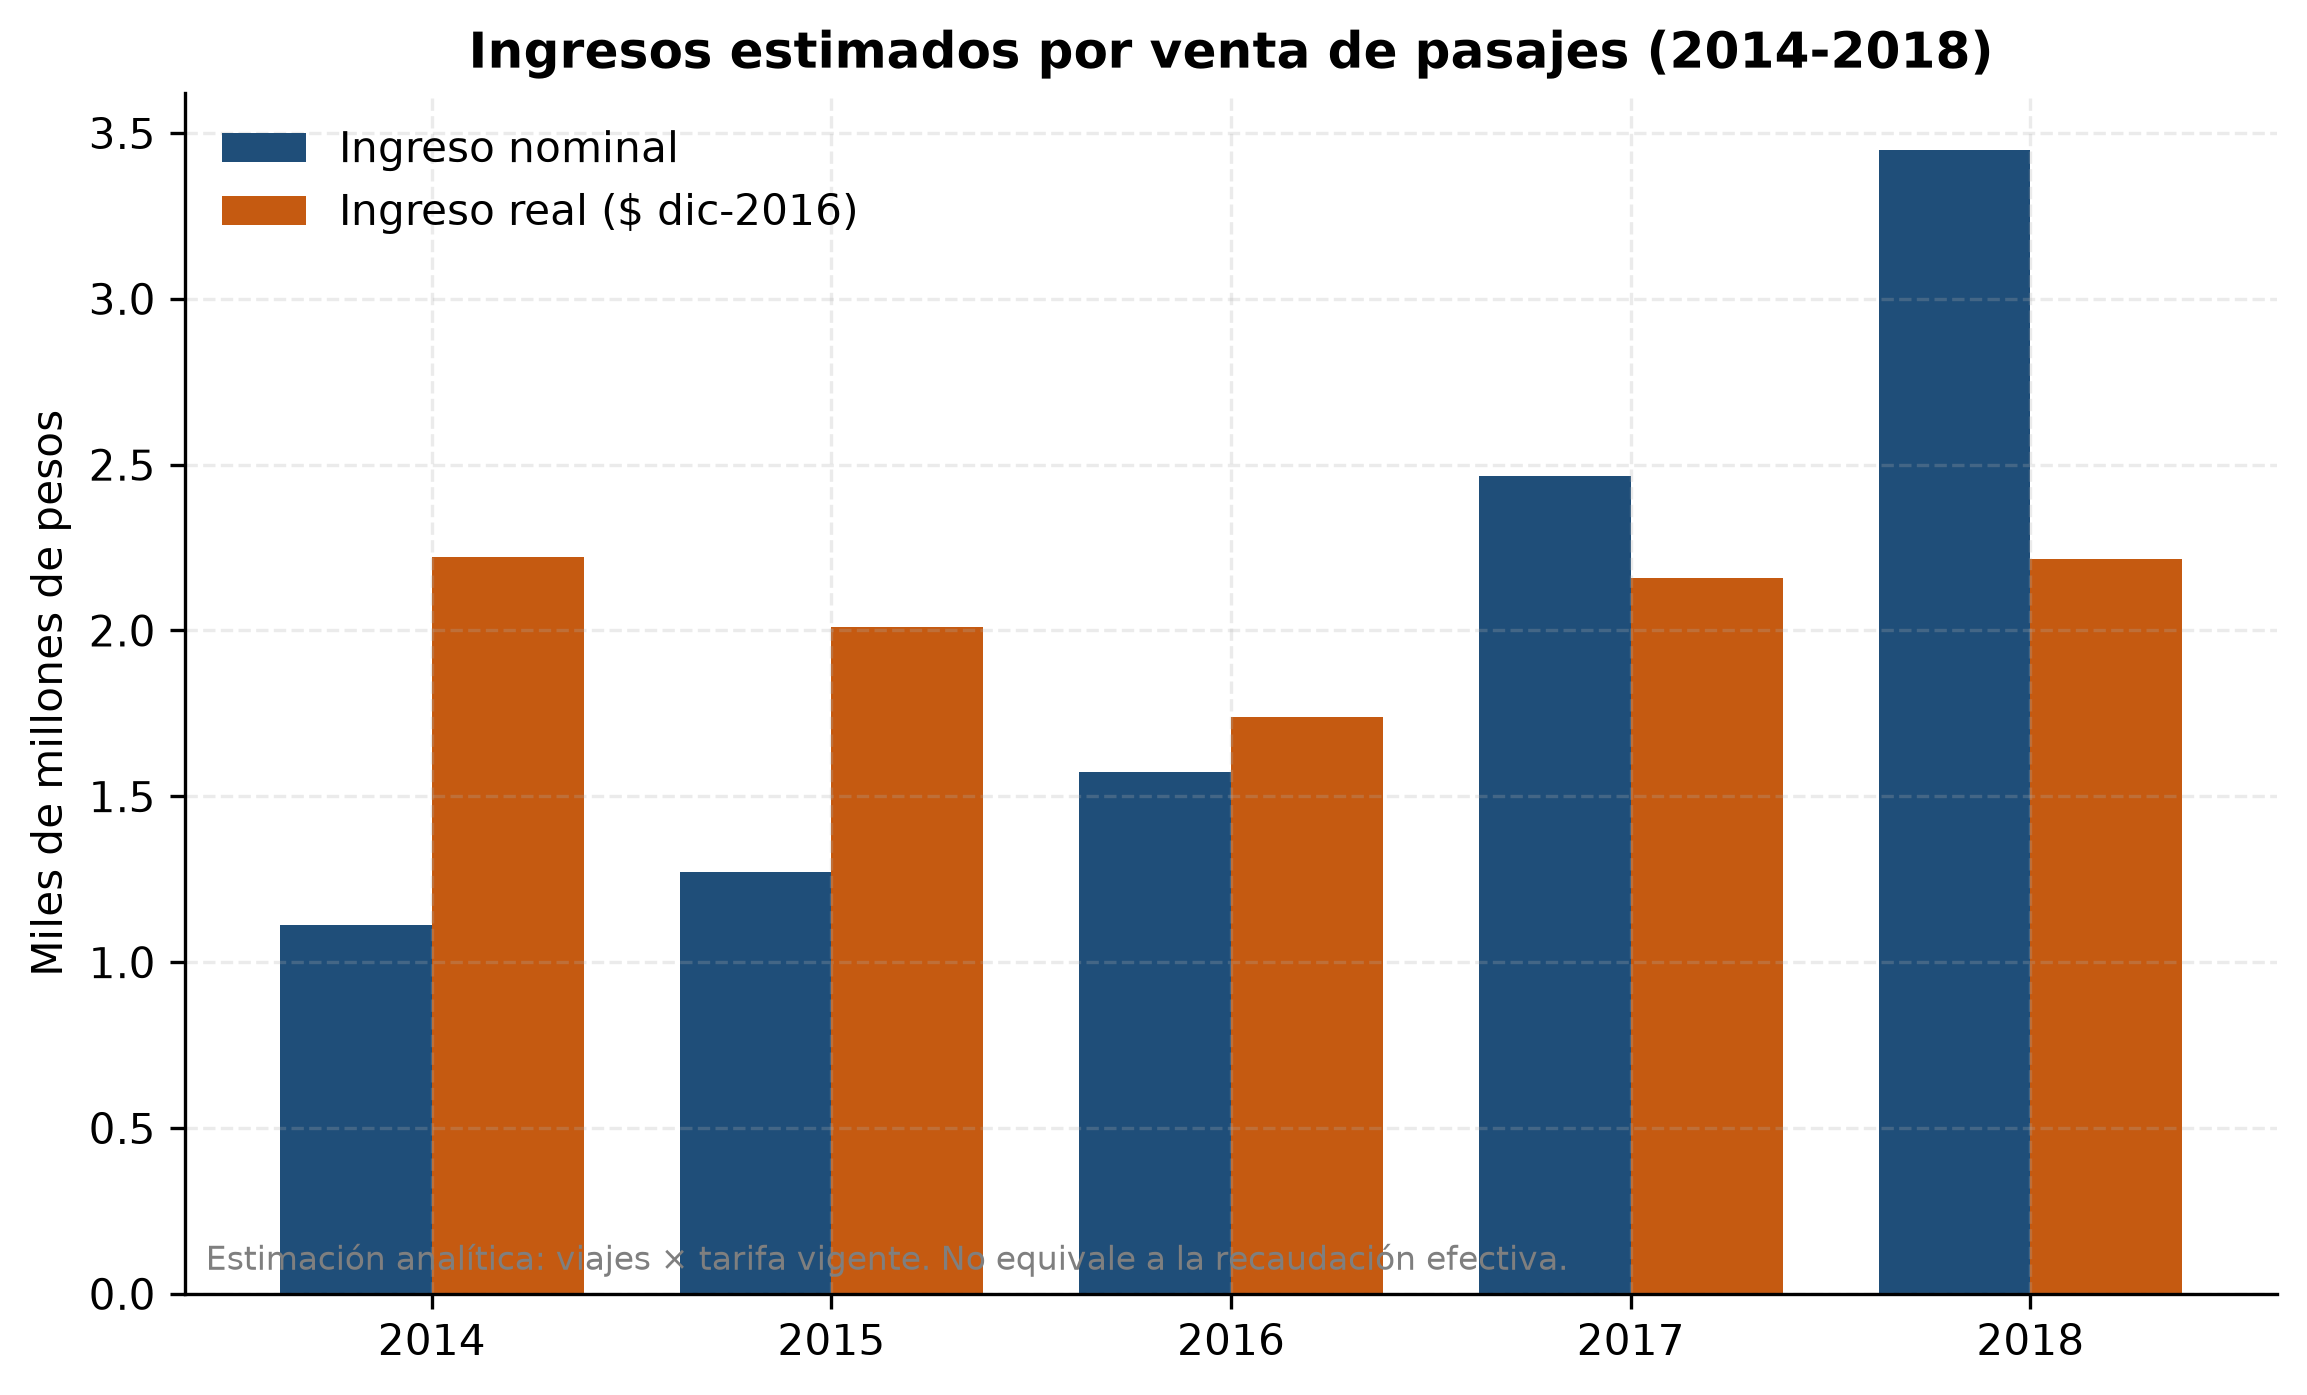

In [9]:
p = datos["panel"].copy()
p = p[p["fecha"] <= "2019-04-01"].copy()
p["ingreso_nominal"] = p["viajes_total"] * p["precio_nominal"]
p["ingreso_real"] = p["ingreso_nominal"] / p["ipc_caba_base_dic2016"] * 100

ingresos = (
    p.groupby("anio")
    .agg(
        viajes=("viajes_total", "sum"),
        ingreso_nominal=("ingreso_nominal", "sum"),
        ingreso_real=("ingreso_real", "sum"),
        meses=("mes", "count"),
    )
    .reset_index()
)
tabla_ingresos = ingresos.copy()
tabla_ingresos["viajes"] = (tabla_ingresos["viajes"] / 1_000_000).round(1)
tabla_ingresos["ingreso_nominal"] = (tabla_ingresos["ingreso_nominal"] / 1_000_000_000).round(2)
tabla_ingresos["ingreso_real"] = (tabla_ingresos["ingreso_real"] / 1_000_000_000).round(2)
tabla_ingresos.columns = [
    "Año", "Viajes (mill.)", "Ingreso nominal (miles de millones $)",
    "Ingreso real (miles de millones $ dic-2016)", "Meses",
]
display(tabla_ingresos)

completo = ingresos[ingresos["meses"] == 12]
print("Variación 2014-2018 del ingreso nominal:", f"{(completo.loc[completo.anio==2018,'ingreso_nominal'].iloc[0]/completo.loc[completo.anio==2014,'ingreso_nominal'].iloc[0]-1)*100:.1f}%")
print("Variación 2014-2018 del ingreso real:", f"{(completo.loc[completo.anio==2018,'ingreso_real'].iloc[0]/completo.loc[completo.anio==2014,'ingreso_real'].iloc[0]-1)*100:.1f}%")
print("2019 corresponde solo a enero-abril.")

display(Image(filename=str(FIG / "fig13_ingresos.png")))

## 9. Síntesis de resultados

Se recuperan los valores principales de `outputs/resultados.json` para cerrar el análisis.

In [10]:
res = json.loads((ROOT / "outputs" / "resultados.json").read_text(encoding="utf-8"))
print("TARIFA")
print(f"  Nominal ene-2014: ${res['tarifa']['tarifa_nominal_2014_01']:.2f}")
print(f"  Nominal abr-2019: ${res['tarifa']['tarifa_nominal_2019_04']:.2f}")
print(f"  Variación nominal: {res['tarifa']['tarifa_nominal_var_pct']:.1f}%")
print(f"  Variación real:    {res['tarifa']['tarifa_real_var_pct']:.1f}%")
print(f"  Inflación CABA:    {res['tarifa']['ipc_var_pct']:.1f}%")
print()
print("DEMANDA")
print(f"  2014: {res['demanda']['demanda_2014']/1e6:.1f} millones")
print(f"  2019: {res['demanda']['demanda_2019']/1e6:.1f} millones")
print(f"  Variación 2014-2019: {res['demanda']['demanda_var_2014_2019_pct']:.1f}%")
print(f"  Estaciones existentes en 2014: {res['demanda']['demanda_existentes_var_pct']:.1f}%")
print(f"  Nuevas estaciones (2019): {res['demanda']['demanda_nuevas_2019']/1e6:.1f} millones")
print(f"  Línea H: {res['demanda']['linea_h_var_pct']:.1f}%")
print()
print("RELACIÓN TARIFA-DEMANDA")
print(f"  Elasticidad principal: {res['relacion']['elasticidad_principal']:.3f}")
print(f"  IC 95%: [{res['relacion']['elasticidad_ic95'][0]:.3f}, {res['relacion']['elasticidad_ic95'][1]:.3f}]")
print(f"  R²: {res['relacion']['elasticidad_r2']:.3f} | N: {res['relacion']['elasticidad_n']}")
print(f"  Correlación YoY contemporánea: {res['relacion']['correlaciones_yoy']['lag_0']:.3f}")
print(f"  Correlación YoY con un rezago: {res['relacion']['correlaciones_yoy']['lag_1']:.3f}")
print()
print("INGRESOS")
print(f"  Variación nominal 2014-2018: {res['ingresos']['ingreso_nominal_var_pct']:.1f}%")
print(f"  Variación real 2014-2018:    {res['ingresos']['ingreso_real_var_pct']:.1f}%")

TARIFA
  Nominal ene-2014: $3.50
  Nominal abr-2019: $19.00
  Variación nominal: 442.9%
  Variación real:    8.4%
  Inflación CABA:    400.6%

DEMANDA
  2014: 255.2 millones
  2019: 341.3 millones
  Variación 2014-2019: 33.8%
  Estaciones existentes en 2014: 28.0%
  Nuevas estaciones (2019): 14.6 millones
  Línea H: 364.6%

RELACIÓN TARIFA-DEMANDA
  Elasticidad principal: -0.168
  IC 95%: [-0.220, -0.116]
  R²: 0.937 | N: 64
  Correlación YoY contemporánea: -0.568
  Correlación YoY con un rezago: -0.598

INGRESOS
  Variación nominal 2014-2018: 209.8%
  Variación real 2014-2018:    -0.3%


### Conclusiones del análisis

1. **La tarifa real no subió tanto como la nominal.** Entre enero de 2014 y abril de 2019 la tarifa nominal pasó de $3,50 a $19,00 (+442,9%), pero la inflación de CABA acumuló +400,6%. En términos reales, la tarifa pasó de $8,25 a $8,95 (base diciembre 2016), solo +8,4%.
2. **La demanda creció, con un cambio de tendencia en 2019.** Los viajes pasaron de 255,2 a 341,3 millones (+33,8%). El crecimiento fue fuerte en 2015-2016, se moderó en 2017-2018 y se volvió negativo en 2019 (-2,0%; -1,2% en promedio diario comparable).
3. **La expansión de la red explica una parte del crecimiento.** Las estaciones existentes en 2014 crecieron +28,0%; las nuevas aportaron 14,6 millones de viajes en 2019. La línea H creció +364,6% y pasó de 2,9% a 10,2% de la demanda.
4. **La relación tarifa-demanda es negativa pero moderada.** La elasticidad estimada es -0,168 (IC 95%: -0,220 a -0,116; R² = 0,937; N = 64). La cifra es una asociación condicional, no un efecto causal.
5. **Los ingresos nominales crecieron fuerte, pero los reales quedaron estancados.** Entre 2014 y 2018 el ingreso nominal estimado aumentó +209,8%, mientras que el ingreso real cayó -0,3%.

El detalle metodológico, las tablas completas y las limitaciones se desarrollan en `docs/informe_final.pdf`.